# Comprehensive Exploratory Data Analysis (EDA) on IPL Dataset (2008–2026)

---

##  Step 1: Problem Definition & Data Understanding

### 1.1 Project Objective
The Indian Premier League (IPL) is the premier global Twenty20 cricket tournament. The objective of this project is to conduct a complete Exploratory Data Analysis over 19 tournament editions (2008–2026) to uncover:
- How T20 batting pacing and scoring thresholds have transformed over time.
- Whether tactical decisions (such as batting first vs. chasing, or electing to field upon winning the toss) confer a true winning advantage.
- How pitch and ground dimensions dictate venue-specific defending par scores.
- How match phases (Powerplay, Middle, Death) differ in run accumulation and dismissal risk.
- Which players and franchises represent benchmarks of sustained historical excellence.

### 1.2 Multi-Granular Dataset Architecture
Our analysis utilizes three interconnected CSV files located in `dataset/`:
- **Match-Level (`ipl_matches_2008_2026.csv`)**: Macro granularity ($1,243$ rows $\times$ $32$ columns). Contains fixture-level outcomes, venues, toss choices, and official innings totals.
- **Delivery-Level (`ipl_ball_by_ball_2008_2026.csv`)**: Micro granularity ($295,732$ rows $\times$ $38$ columns). Contains ball-by-ball actions, runs, extra types, wickets, and DRS review events.
- **Player-Season Level (`ipl_player_season_stats_2008_2026.csv`)**: Meso granularity ($3,339$ rows $\times$ $24$ columns). Contains seasonal batting and bowling totals and rates.

## Step 2: Data Ingestion & Initial Structural Exploration

In [1]:
#file paths
match_path = r"dataset\ipl_matches_2008_2026.csv"
ball_path = r"dataset\ipl_ball_by_ball_2008_2026.csv"
player_path = r"dataset\ipl_player_season_stats_2008_2026.csv"

In [2]:
#Load Datasets
import pandas as pd
matches_df = pd.read_csv(match_path)
ball_df = pd.read_csv(ball_path)
player_season_df = pd.read_csv(player_path)

print(f"1. Match Table : {matches_df.shape[0]} rows x {matches_df.shape[1]} columns")
print(f"2. Ball by Ball Table : {ball_df.shape[0]} rows x {ball_df.shape[1]} columns")
print(f"3. Player Season start Table : {player_season_df.shape[0]} rows x {player_season_df.shape[1]} columns")

1. Match Table : 1243 rows x 32 columns
2. Ball by Ball Table : 295732 rows x 38 columns
3. Player Season start Table : 3339 rows x 24 columns


C:\Users\hp\AppData\Local\Temp\ipykernel_13228\4260487349.py:4: DtypeWarning: Columns (36,37) have mixed types. Specify dtype option on import or set low_memory=False.
  ball_df = pd.read_csv(ball_path)


### Matches table preview

In [3]:
#Preview Sample Records
matches_df.head(5)

,match_id,season,date,match_number,stage,city,venue,country,team1,team2,...,result,winner,win_by_runs,win_by_wickets,method,toss_winner_won,player_of_match,umpire1,umpire2,impact_players
0,335982,2008,18-04-2008,1,League,Bengaluru,M Chinnaswamy Stadium,India,Royal Challengers Bengaluru,Kolkata Knight Riders,...,Normal,Kolkata Knight Riders,140.0,NaN,NaN,False,BB McCullum,Asad Rauf,RE Koertzen,NaN
1,335983,2008,19-04-2008,2,League,Mohali,"Punjab Cricket Association IS Bindra Stadium, ...",India,Punjab Kings,Chennai Super Kings,...,Normal,Chennai Super Kings,33.0,NaN,NaN,True,MEK Hussey,MR Benson,SL Shastri,NaN
2,335984,2008,19-04-2008,3,League,Delhi,Arun Jaitley Stadium,India,Delhi Capitals,Rajasthan Royals,...,Normal,Delhi Capitals,NaN,9.0,NaN,False,MF Maharoof,Aleem Dar,GA Pratapkumar,NaN
3,335985,2008,20-04-2008,4,League,Mumbai,Wankhede Stadium,India,Mumbai Indians,Royal Challengers Bengaluru,...,Normal,Royal Challengers Bengaluru,NaN,5.0,NaN,False,MV Boucher,SJ Davis,DJ Harper,NaN
4,335986,2008,20-04-2008,5,League,Kolkata,Eden Gardens,India,Kolkata Knight Riders,Deccan Chargers,...,Normal,Kolkata Knight Riders,NaN,5.0,NaN,False,DJ Hussey,BF Bowden,K Hariharan,NaN


In [4]:
matches_df[['match_id', 'season', 'date', 'stage', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result']].head()

,match_id,season,date,stage,city,venue,team1,team2,toss_winner,toss_decision,winner,result
0,335982,2008,18-04-2008,League,Bengaluru,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders,Normal
1,335983,2008,19-04-2008,League,Mohali,"Punjab Cricket Association IS Bindra Stadium, ...",Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,Normal
2,335984,2008,19-04-2008,League,Delhi,Arun Jaitley Stadium,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,bat,Delhi Capitals,Normal
3,335985,2008,20-04-2008,League,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,bat,Royal Challengers Bengaluru,Normal
4,335986,2008,20-04-2008,League,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,Normal


In [5]:
matches_df[['match_id', 'season', 'date', 'stage', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result']].tail()

,match_id,season,date,stage,city,venue,team1,team2,toss_winner,toss_decision,winner,result
1238,1529313,2026,24-05-2026,League,Kolkata,Eden Gardens,Delhi Capitals,Kolkata Knight Riders,Kolkata Knight Riders,field,Delhi Capitals,Normal
1239,1535462,2026,26-05-2026,Qualifier 1,Dharamsala,HPCA Stadium,Royal Challengers Bengaluru,Gujarat Titans,Gujarat Titans,field,Royal Challengers Bengaluru,Normal
1240,1535463,2026,27-05-2026,Eliminator,New Chandigarh,Maharaja Yadavindra Singh International Cricke...,Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Rajasthan Royals,Normal
1241,1535464,2026,29-05-2026,Qualifier 2,New Chandigarh,Maharaja Yadavindra Singh International Cricke...,Rajasthan Royals,Gujarat Titans,Rajasthan Royals,bat,Gujarat Titans,Normal
1242,1535465,2026,31-05-2026,Final,Ahmedabad,Narendra Modi Stadium (Motera),Gujarat Titans,Royal Challengers Bengaluru,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,Normal


In [6]:
matches_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   match_id                1243 non-null   int64  
 1   season                  1243 non-null   int64  
 2   date                    1243 non-null   object 
 3   match_number            1243 non-null   int64  
 4   stage                   1243 non-null   object 
 5   city                    1243 non-null   object 
 6   venue                   1243 non-null   object 
 7   country                 1243 non-null   object 
 8   team1                   1243 non-null   object 
 9   team2                   1243 non-null   object 
 10  toss_winner             1243 non-null   object 
 11  toss_decision           1243 non-null   object 
 12  batting_first           1243 non-null   object 
 13  batting_second          1243 non-null   object 
 14  first_innings_runs      1243 non-null   

In [7]:
matches_df.describe()

,match_id,season,match_number,first_innings_runs,first_innings_wickets,first_innings_overs,second_innings_runs,second_innings_wickets,second_innings_overs,target_runs,target_overs,win_by_runs,win_by_wickets
count,1.243000e+03,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1237.000000,1237.000000,1237.000000,1237.000000,1237.000000,558.000000,660.000000
mean,9.758619e+05,2017.242156,33.605792,168.569590,6.123894,19.765245,155.126112,5.693614,18.344624,168.992724,19.773808,31.035842,6.171212
std,3.956922e+05,5.550682,19.575586,34.053296,2.129639,1.232752,33.460409,2.741695,2.577482,35.036400,1.517522,27.162827,1.834442
min,3.359820e+05,2008.000000,1.000000,25.000000,0.000000,3.400000,2.000000,0.000000,1.000000,43.000000,5.000000,1.000000,1.000000
25%,5.483705e+05,2012.000000,17.000000,148.000000,4.500000,20.000000,136.000000,4.000000,18.100000,148.000000,20.000000,11.000000,5.000000
50%,1.082636e+06,2017.000000,33.000000,168.000000,6.000000,20.000000,157.000000,6.000000,19.300000,169.000000,20.000000,23.000000,6.000000
75%,1.304102e+06,2022.000000,50.000000,190.000000,8.000000,20.000000,177.000000,8.000000,20.000000,191.000000,20.000000,43.000000,7.000000
max,1.535465e+06,2026.000000,76.000000,287.000000,10.000000,20.100000,265.000000,10.000000,20.000000,288.000000,20.000000,146.000000,10.000000


### Ball by Ball table preview

In [8]:
ball_df.head()

,match_id,season,date,venue,innings,is_super_over,batting_team,bowling_team,over,ball,...,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate,review_by,review_decision
0,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,...,1,0,1,6.0,NaN,NaN,NaN,NaN,NaN,NaN
1,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,...,1,0,2,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,2,0,2,6.0,NaN,NaN,NaN,NaN,NaN,NaN
3,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,2,0,3,4.0,NaN,NaN,NaN,NaN,NaN,NaN
4,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,4,...,2,0,4,3.0,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
ball_df[['match_id', 'season', 'venue', 'innings', 'over', 'ball', 'phase', 'batter', 'bowler', 'total_runs', 'is_wicket']].tail()

,match_id,season,venue,innings,over,ball,phase,batter,bowler,total_runs,is_wicket
295727,1535465,2026,Narendra Modi Stadium (Motera),2,18,2,Death,V Kohli,Arshad Khan,1,False
295728,1535465,2026,Narendra Modi Stadium (Motera),2,18,3,Death,JM Sharma,Arshad Khan,0,False
295729,1535465,2026,Narendra Modi Stadium (Motera),2,18,4,Death,JM Sharma,Arshad Khan,1,False
295730,1535465,2026,Narendra Modi Stadium (Motera),2,18,5,Death,V Kohli,Arshad Khan,4,False
295731,1535465,2026,Narendra Modi Stadium (Motera),2,18,6,Death,V Kohli,Arshad Khan,6,False


In [10]:
ball_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295732 entries, 0 to 295731
Data columns (total 38 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   match_id            295732 non-null  int64  
 1   season              295732 non-null  int64  
 2   date                295732 non-null  object 
 3   venue               295732 non-null  object 
 4   innings             295732 non-null  int64  
 5   is_super_over       295732 non-null  bool   
 6   batting_team        295732 non-null  object 
 7   bowling_team        295732 non-null  object 
 8   over                295732 non-null  int64  
 9   ball                295732 non-null  int64  
 10  delivery_in_over    295732 non-null  int64  
 11  phase               295732 non-null  object 
 12  batter              295732 non-null  object 
 13  non_striker         295732 non-null  object 
 14  bowler              295732 non-null  object 
 15  batter_runs         295732 non-nul

In [11]:
ball_df.describe()

,match_id,season,innings,over,ball,delivery_in_over,batter_runs,extra_runs,total_runs,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate
count,2.957320e+05,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295732.000000,295567.000000,142303.000000,142303.000000,142303.000000,141819.000000
mean,9.770551e+05,2017.260753,1.482728,10.190331,3.488807,3.629195,1.290117,0.068336,1.358453,78.146291,2.466067,58.592844,7.786347,171.548400,95.298553,62.362621,10.949949
std,3.953255e+05,5.543147,0.502436,5.679690,1.708185,1.819312,1.664418,0.342939,1.650191,50.698248,2.105231,34.106127,2.509778,33.079009,52.058153,33.413922,13.452173
min,3.359820e+05,2008.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,43.000000,0.000000,0.000000,0.000000
25%,5.483720e+05,2012.000000,1.000000,5.000000,2.000000,2.000000,0.000000,0.000000,0.000000,36.000000,1.000000,29.000000,6.440000,151.000000,54.000000,34.000000,7.370000
50%,1.082639e+06,2017.000000,1.000000,10.000000,3.000000,4.000000,1.000000,0.000000,1.000000,74.000000,2.000000,58.000000,7.740000,170.000000,94.000000,63.000000,9.150000
75%,1.304103e+06,2022.000000,2.000000,15.000000,5.000000,5.000000,1.000000,0.000000,1.000000,115.000000,4.000000,88.000000,9.070000,192.000000,134.000000,91.000000,11.390000
max,1.535465e+06,2026.000000,6.000000,20.000000,7.000000,11.000000,6.000000,7.000000,7.000000,287.000000,10.000000,121.000000,66.000000,288.000000,287.000000,120.000000,792.000000


### Player season table preview

In [12]:
player_season_df.head()

,season,player,team,matches,innings_batted,runs,balls_faced,highest_score,batting_avg,strike_rate,...,dismissals,overs_bowled,balls_bowled,runs_conceded,wickets,economy,bowling_avg,best_bowling,dot_balls,player_of_match_awards
0,2008,SE Marsh,Punjab Kings,11,11,616,441,115,68.44,139.68,...,9,NaN,0,0,0,NaN,NaN,NaN,0,5
1,2008,G Gambhir,Delhi Capitals,14,14,534,379,86,41.08,140.90,...,13,NaN,0,0,0,NaN,NaN,NaN,0,0
2,2008,ST Jayasuriya,Mumbai Indians,14,14,514,309,114,42.83,166.34,...,12,21.0,126,159,4,7.57,39.75,Mar-14,36,2
3,2008,SR Watson,Rajasthan Royals,15,15,472,311,76,47.20,151.77,...,10,54.1,325,383,17,7.07,22.53,03-Oct,158,4
4,2008,GC Smith,Rajasthan Royals,11,11,441,362,91,49.00,121.82,...,9,NaN,0,0,0,NaN,NaN,NaN,0,1


In [13]:
player_season_df[['season', 'player', 'team', 'matches', 'runs', 'balls_faced', 'strike_rate', 'wickets', 'economy']].head()

,season,player,team,matches,runs,balls_faced,strike_rate,wickets,economy
0,2008,SE Marsh,Punjab Kings,11,616,441,139.68,0,NaN
1,2008,G Gambhir,Delhi Capitals,14,534,379,140.90,0,NaN
2,2008,ST Jayasuriya,Mumbai Indians,14,514,309,166.34,4,7.57
3,2008,SR Watson,Rajasthan Royals,15,472,311,151.77,17,7.07
4,2008,GC Smith,Rajasthan Royals,11,441,362,121.82,0,NaN


In [14]:
player_season_df[['season', 'player', 'team', 'matches', 'runs', 'balls_faced', 'strike_rate', 'wickets', 'economy']].tail()

,season,player,team,matches,runs,balls_faced,strike_rate,wickets,economy
3334,2026,Suyash Sharma,Royal Challengers Bengaluru,12,0,0,NaN,9,9.21
3335,2026,T Vijay,Delhi Capitals,1,0,0,NaN,0,14.50
3336,2026,YS Chahal,Punjab Kings,12,0,0,NaN,12,9.39
3337,2026,Yash Raj Punja,Rajasthan Royals,8,0,0,NaN,9,9.30
3338,2026,Yash Thakur,Punjab Kings,1,0,0,NaN,2,13.75


In [15]:
player_season_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3339 entries, 0 to 3338
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   season                  3339 non-null   int64  
 1   player                  3339 non-null   object 
 2   team                    3339 non-null   object 
 3   matches                 3339 non-null   int64  
 4   innings_batted          3339 non-null   int64  
 5   runs                    3339 non-null   int64  
 6   balls_faced             3339 non-null   int64  
 7   highest_score           3339 non-null   int64  
 8   batting_avg             2659 non-null   float64
 9   strike_rate             2959 non-null   float64
 10  fifties                 3339 non-null   int64  
 11  hundreds                3339 non-null   int64  
 12  fours                   3339 non-null   int64  
 13  sixes                   3339 non-null   int64  
 14  dismissals              3339 non-null   

In [16]:
player_season_df.describe()

,season,matches,innings_batted,runs,balls_faced,highest_score,batting_avg,strike_rate,fifties,hundreds,...,sixes,dismissals,overs_bowled,balls_bowled,runs_conceded,wickets,economy,bowling_avg,dot_balls,player_of_match_awards
count,3339.000000,3339.000000,3339.000000,3339.000000,3339.000000,3339.000000,2659.000000,2959.000000,3339.000000,3339.000000,...,3339.000000,3339.00000,2201.000000,3339.000000,3339.000000,3339.000000,2201.000000,1811.000000,3339.000000,3339.000000
mean,2017.254268,7.925427,5.620845,114.176400,85.560347,30.221923,19.918996,111.535461,0.595987,0.037436,...,4.718479,4.38814,21.485007,85.194669,118.074873,4.031147,9.095547,36.227046,30.304882,0.369572
std,5.625978,4.990717,5.020330,156.048739,110.320847,31.276251,15.135381,49.855820,1.241144,0.223218,...,7.538783,4.42171,18.051164,107.261918,143.589682,5.804349,2.623093,23.316394,40.854202,0.729821
min,2008.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2012.000000,3.000000,1.000000,4.000000,6.000000,3.000000,8.000000,85.825000,0.000000,0.000000,...,0.000000,1.00000,6.000000,0.000000,0.000000,0.000000,7.540000,22.550000,0.000000,0.000000
50%,2017.000000,8.000000,4.000000,34.000000,30.000000,19.000000,18.000000,117.820000,0.000000,0.000000,...,1.000000,3.00000,16.000000,33.000000,52.000000,1.000000,8.620000,29.670000,10.000000,0.000000
75%,2022.000000,13.000000,10.000000,182.000000,135.000000,52.000000,29.000000,140.000000,1.000000,0.000000,...,7.000000,8.00000,35.400000,140.500000,202.500000,6.000000,10.000000,41.225000,49.000000,1.000000
max,2026.000000,19.000000,19.000000,973.000000,640.000000,175.000000,152.000000,400.000000,9.000000,4.000000,...,72.000000,18.00000,70.000000,420.000000,626.000000,32.000000,36.000000,248.000000,211.000000,6.000000


In [17]:
datasets = {
    "Ball-by-ball": ball_df,
    "Matches": matches_df,
    "Player statistics": player_season_df
}

for name, df in datasets.items():
    numerical = df.select_dtypes(include="number").columns
    categorical = df.select_dtypes(include=["object", "category"]).columns
    datetime_cols = df.select_dtypes(include="datetime").columns

    print(f"\n{name}")
    print("Total rows:", df.shape[0])
    print("Total columns:", df.shape[1])
    print("Numerical columns:", len(numerical))
    print("Categorical columns:", len(categorical))
    print("Datetime columns:", len(datetime_cols))


Ball-by-ball
Total rows: 295732
Total columns: 38
Numerical columns: 17
Categorical columns: 14
Datetime columns: 0

Matches
Total rows: 1243
Total columns: 32
Numerical columns: 13
Categorical columns: 19
Datetime columns: 0

Player statistics
Total rows: 3339
Total columns: 24
Numerical columns: 21
Categorical columns: 3
Datetime columns: 0


## Step 3: Systematic Data Cleaning & Preprocessing 

Check unique values in important columns

In [18]:

for col in ["season", "batting_team", "bowling_team", "inning"]:
    if col in ball_df.columns:
        print(f"\nBall-by-ball: {col}")
        print("Unique values:", ball_df[col].nunique())
        print(ball_df[col].value_counts().head(10))





Ball-by-ball: season
Unique values: 19
season
2013    18177
2022    17912
2023    17863
2012    17767
2026    17527
2025    17285
2024    17103
2011    17013
2020    14559
2010    14498
Name: count, dtype: int64

Ball-by-ball: batting_team
Unique values: 15
batting_team
Mumbai Indians                 34990
Royal Challengers Bengaluru    33572
Delhi Capitals                 33107
Punjab Kings                   33100
Kolkata Knight Riders          32463
Chennai Super Kings            32101
Rajasthan Royals               29777
Sunrisers Hyderabad            25284
Gujarat Titans                  9379
Deccan Chargers                 9034
Name: count, dtype: int64

Ball-by-ball: bowling_team
Unique values: 15
bowling_team
Mumbai Indians                 35076
Royal Challengers Bengaluru    33827
Delhi Capitals                 33211
Kolkata Knight Riders          32797
Punjab Kings                   32729
Chennai Super Kings            31849
Rajasthan Royals               30127
Sunrisers Hyde

In [19]:
for col in ["season", "team1", "team2", "venue", "winner"]:
    if col in matches_df.columns:
        print(f"\nMatches: {col}")
        print("Unique values:", matches_df[col].nunique())
        print(matches_df[col].value_counts().head(10))



Matches: season
Unique values: 19
season
2013    76
2012    74
2026    74
2023    74
2025    74
2022    74
2011    73
2024    71
2014    60
2010    60
Name: count, dtype: int64

Matches: team1
Unique values: 15
team1
Royal Challengers Bengaluru    159
Chennai Super Kings            142
Punjab Kings                   139
Mumbai Indians                 139
Delhi Capitals                 137
Kolkata Knight Riders          134
Rajasthan Royals               115
Sunrisers Hyderabad            104
Lucknow Super Giants            41
Deccan Chargers                 39
Name: count, dtype: int64

Matches: team2
Unique values: 15
team2
Mumbai Indians                 152
Delhi Capitals                 144
Kolkata Knight Riders          144
Punjab Kings                   139
Rajasthan Royals               136
Royal Challengers Bengaluru    127
Chennai Super Kings            124
Sunrisers Hyderabad            107
Gujarat Titans                  43
Deccan Chargers                 36
Name: count, dty

In [20]:
for col in ["season", "player", "team"]:
    if col in player_season_df.columns:
        print(f"\nPlayer statistics: {col}")
        print("Unique values:", player_season_df[col].nunique())
        print(player_season_df[col].value_counts().head(10))


Player statistics: season
Unique values: 19
season
2023    209
2024    209
2026    202
2025    200
2011    198
2013    196
2022    190
2012    188
2010    179
2021    168
Name: count, dtype: int64

Player statistics: player
Unique values: 806
player
RG Sharma     19
V Kohli       19
MK Pandey     19
RA Jadeja     18
AM Rahane     18
MS Dhoni      18
S Dhawan      17
JD Unadkat    17
WP Saha       17
KD Karthik    17
Name: count, dtype: int64

Player statistics: team
Unique values: 15
team
Delhi Capitals                 389
Royal Challengers Bengaluru    388
Punjab Kings                   386
Mumbai Indians                 384
Kolkata Knight Riders          369
Rajasthan Royals               345
Chennai Super Kings            318
Sunrisers Hyderabad            278
Lucknow Super Giants           105
Deccan Chargers                101
Name: count, dtype: int64


Check missing values in each dataset

In [21]:
print("Ball by Ball missing values :")
ball_df.isnull().sum().sort_values(ascending=False)


Ball by Ball missing values :


review_decision       294742
review_by             294742
fielders              285011
dismissal_kind        281027
player_out            281027
extra_type            279505
required_run_rate     153913
balls_left            153429
target                153429
runs_needed           153429
current_run_rate         165
match_id                   0
season                     0
date                       0
is_super_over              0
innings                    0
venue                      0
batting_team               0
delivery_in_over           0
phase                      0
over                       0
bowling_team               0
is_six                     0
is_four                    0
is_legal_ball              0
total_runs                 0
batter_runs                0
extra_runs                 0
bowler                     0
non_striker                0
ball                       0
batter                     0
team_wickets               0
is_dot                     0
is_wicket     

In [22]:
print("Matches missing values:")
matches_df.isnull().sum().sort_values(ascending = False)

Matches missing values:


method                    1220
impact_players             952
win_by_runs                685
win_by_wickets             583
toss_winner_won              9
player_of_match              9
winner                       9
second_innings_runs          6
target_overs                 6
target_runs                  6
second_innings_overs         6
second_innings_wickets       6
match_id                     0
season                       0
date                         0
match_number                 0
first_innings_wickets        0
first_innings_runs           0
batting_second               0
batting_first                0
toss_decision                0
toss_winner                  0
team2                        0
team1                        0
country                      0
venue                        0
city                         0
stage                        0
result                       0
first_innings_overs          0
umpire1                      0
umpire2                      0
dtype: i

In [23]:

print("Player statistics missing values:")
player_season_df.isnull().sum().sort_values(ascending = False)

Player statistics missing values:


bowling_avg               1528
best_bowling              1138
overs_bowled              1138
economy                   1138
batting_avg                680
strike_rate                380
season                       0
player                       0
highest_score                0
balls_faced                  0
runs                         0
innings_batted               0
matches                      0
team                         0
hundreds                     0
fifties                      0
dismissals                   0
sixes                        0
fours                        0
balls_bowled                 0
wickets                      0
runs_conceded                0
dot_balls                    0
player_of_match_awards       0
dtype: int64

In [24]:
display(
    player_season_df[
        player_season_df["bowling_avg"].isna()
    ][
        ["player", "season", "matches", "innings_batted",
         "balls_bowled", "wickets", "runs_conceded",
         "bowling_avg"]
    ].head(20)
)

,player,season,matches,innings_batted,balls_bowled,wickets,runs_conceded,bowling_avg
0,SE Marsh,2008,11,11,0,0,0,NaN
1,G Gambhir,2008,14,14,0,0,0,NaN
4,GC Smith,2008,11,11,0,0,0,NaN
5,AC Gilchrist,2008,14,14,0,0,0,NaN
8,MS Dhoni,2008,14,14,0,0,0,NaN
11,R Dravid,2008,14,14,0,0,0,NaN
13,S Dhawan,2008,14,14,0,0,0,NaN
14,KC Sangakkara,2008,9,9,0,0,0,NaN
15,RV Uthappa,2008,14,14,0,0,0,NaN
17,SA Asnodkar,2008,9,9,0,0,0,NaN


In [25]:
display(
    player_season_df[
        player_season_df["bowling_avg"].isna()
    ][["balls_bowled", "wickets", "runs_conceded"]]
    .describe()
)

,balls_bowled,wickets,runs_conceded
count,1528.000000,1528.0,1528.000000
mean,5.191099,0.0,9.045812
std,12.404031,0.0,21.288408
min,0.000000,0.0,0.000000
25%,0.000000,0.0,0.000000
50%,0.000000,0.0,0.000000
75%,2.000000,0.0,4.250000
max,108.000000,0.0,210.000000


In [26]:
# Check missing bowling averages with no bowling activity
display(
    player_season_df[
        player_season_df["bowling_avg"].isna()
        & (player_season_df["balls_bowled"] == 0)
        & (player_season_df["wickets"] == 0)
    ][
        ["player", "season", "balls_bowled",
         "wickets", "runs_conceded", "bowling_avg"]
    ].head(10)
)

,player,season,balls_bowled,wickets,runs_conceded,bowling_avg
0,SE Marsh,2008,0,0,0,NaN
1,G Gambhir,2008,0,0,0,NaN
4,GC Smith,2008,0,0,0,NaN
5,AC Gilchrist,2008,0,0,0,NaN
8,MS Dhoni,2008,0,0,0,NaN
11,R Dravid,2008,0,0,0,NaN
13,S Dhawan,2008,0,0,0,NaN
14,KC Sangakkara,2008,0,0,0,NaN
15,RV Uthappa,2008,0,0,0,NaN
17,SA Asnodkar,2008,0,0,0,NaN


In [27]:
# Count records with no wickets but some bowling activity
display(
    player_season_df[
        player_season_df["bowling_avg"].isna()
        & (player_season_df["wickets"] == 0)
    ].groupby(
        player_season_df["balls_bowled"] > 0
    ).size()
)

balls_bowled
False    1138
True      390
dtype: int64

In [28]:
display(
    player_season_df[
        player_season_df["bowling_avg"].isna()
        & (player_season_df["balls_bowled"] > 0)
    ][
        ["player", "season", "balls_bowled",
         "wickets", "runs_conceded", "bowling_avg"]
    ].head(20)
)

,player,season,balls_bowled,wickets,runs_conceded,bowling_avg
39,A Symonds,2008,41,0,101,NaN
47,RA Jadeja,2008,13,0,21,NaN
53,CL White,2008,6,0,24,NaN
66,K Goel,2008,12,0,25,NaN
78,LPC Silva,2008,6,0,21,NaN
108,CK Kapugedera,2008,17,0,49,NaN
123,Pankaj Singh,2008,72,0,129,NaN
142,VS Yeligati,2008,30,0,59,NaN
144,Iqbal Abdulla,2008,18,0,22,NaN
149,Abdur Razzak,2008,12,0,29,NaN


In [29]:
def missing_report(df, name):
    report = pd.DataFrame({
        "missing_count": df.isnull().sum(),
        "missing_percent": df.isnull().mean() * 100
    })

    report = report[report["missing_count"] > 0]
    report = report.sort_values(
        "missing_percent", ascending=False
    )

    print(f"\n{name}")
    display(report.round(2))

    print("\nColumns with more than 80% missing values:")
    display(report[report["missing_percent"] > 80])


missing_report(ball_df, "Ball-by-ball")
missing_report(matches_df, "Matches")
missing_report(player_season_df, "Player statistics")


Ball-by-ball


,missing_count,missing_percent
review_by,294742,99.67
review_decision,294742,99.67
fielders,285011,96.37
player_out,281027,95.03
dismissal_kind,281027,95.03
extra_type,279505,94.51
required_run_rate,153913,52.04
target,153429,51.88
runs_needed,153429,51.88
balls_left,153429,51.88



Columns with more than 80% missing values:


,missing_count,missing_percent
review_by,294742,99.665237
review_decision,294742,99.665237
fielders,285011,96.374758
player_out,281027,95.027593
dismissal_kind,281027,95.027593
extra_type,279505,94.512937



Matches


...

,missing_count,missing_percent
method,1220,98.149638



Player statistics


,missing_count,missing_percent
bowling_avg,1528,45.76
overs_bowled,1138,34.08
economy,1138,34.08
best_bowling,1138,34.08
batting_avg,680,20.37
strike_rate,380,11.38



Columns with more than 80% missing values:


,missing_count,missing_percent


## clean the ball by ball table

In [30]:
ball_df.head()

,match_id,season,date,venue,innings,is_super_over,batting_team,bowling_team,over,ball,...,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate,review_by,review_decision
0,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,...,1,0,1,6.0,NaN,NaN,NaN,NaN,NaN,NaN
1,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,...,1,0,2,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,2,0,2,6.0,NaN,NaN,NaN,NaN,NaN,NaN
3,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,2,0,3,4.0,NaN,NaN,NaN,NaN,NaN,NaN
4,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,4,...,2,0,4,3.0,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
ball_df.loc[ball_df[['target', 'runs_needed', 'balls_left', 'required_run_rate']].notna().all(axis=1),['target', 'runs_needed', 'balls_left', 'required_run_rate']].head(5)

,target,runs_needed,balls_left,required_run_rate
124,223.0,222.0,119.0,11.19
125,223.0,221.0,119.0,11.14
126,223.0,221.0,118.0,11.24
127,223.0,220.0,117.0,11.28
128,223.0,219.0,116.0,11.33


In [32]:
ball_df.drop(
    columns=["review_by", "review_decision"],
    inplace=True
)

In [33]:
ball_df.head(5)

,match_id,season,date,venue,innings,is_super_over,batting_team,bowling_team,over,ball,...,fielders,bowler_wicket,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate
0,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,...,NaN,False,1,0,1,6.0,NaN,NaN,NaN,NaN
1,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,...,NaN,False,1,0,2,3.0,NaN,NaN,NaN,NaN
2,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,NaN,False,2,0,2,6.0,NaN,NaN,NaN,NaN
3,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,NaN,False,2,0,3,4.0,NaN,NaN,NaN,NaN
4,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,4,...,NaN,False,2,0,4,3.0,NaN,NaN,NaN,NaN


In [34]:
# 1. Target: keep NaN outside the second innings
# No replacement needed.

# 2. Runs needed: keep NaN outside the second innings
# No replacement needed.

# 3. Balls left: keep NaN outside the second innings
# No replacement needed.
# Do not calculate 120 - legal_balls_bowled here,
# because balls_left represents balls remaining in a chase.

# 4. Required run rate: recalculate where balls remain
mask = (
    ball_df["innings"].eq(2)
    & ball_df["balls_left"].gt(0)
)

ball_df.loc[mask, "required_run_rate"] = (
    ball_df.loc[mask, "runs_needed"] * 6
    / ball_df.loc[mask, "balls_left"]
)

# Keep RRR as NaN when no balls remain.
# Do not use 999 as an artificial rate.

In [35]:
display(
    ball_df.loc[
        ball_df["innings"] > 2,
        [
            "match_id", "innings", "is_super_over",
            "team_score", "target", "runs_needed",
            "balls_left", "required_run_rate"
        ]
    ].head(20)
)

display(
    ball_df.loc[ball_df["innings"] > 2]
    .groupby(["innings", "is_super_over"])
    .agg(
        deliveries=("match_id", "size"),
        matches=("match_id", "nunique")
    )
)

,match_id,innings,is_super_over,team_score,target,runs_needed,balls_left,required_run_rate
15417,392190,3,True,1,NaN,NaN,NaN,NaN
15418,392190,3,True,2,NaN,NaN,NaN,NaN
15419,392190,3,True,3,NaN,NaN,NaN,NaN
15420,392190,3,True,7,NaN,NaN,NaN,NaN
15421,392190,3,True,11,NaN,NaN,NaN,NaN
15422,392190,3,True,15,NaN,NaN,NaN,NaN
15423,392190,3,True,15,NaN,NaN,NaN,NaN
15424,392190,4,True,6,NaN,NaN,NaN,NaN
15425,392190,4,True,8,NaN,NaN,NaN,NaN
15426,392190,4,True,14,NaN,NaN,NaN,NaN


,,deliveries,matches
innings,is_super_over,,
3,True,86,16
4,True,77,16
5,True,8,1
6,True,4,1


In [36]:
# Check missing values in regular innings vs Super Overs
display(
    ball_df.groupby("is_super_over")[
        ["target", "runs_needed", "balls_left", "required_run_rate"]
    ].agg(lambda col: col.isna().sum())
)

,target,runs_needed,balls_left,required_run_rate
is_super_over,,,,
False,153254,153254,153254,153738
True,175,175,175,175


In [37]:
display(
    ball_df.groupby(["innings", "is_super_over"])[
        ["target", "runs_needed", "balls_left", "required_run_rate"]
    ].agg(
        total_rows=("target", "size"),
        missing_runs_needed=("runs_needed", lambda x: x.isna().sum()),
        missing_balls_left=("balls_left", lambda x: x.isna().sum()),
        missing_required_run_rate=(
            "required_run_rate", lambda x: x.isna().sum()
        )
    )
)

,,total_rows,missing_runs_needed,missing_balls_left,missing_required_run_rate
innings,is_super_over,,,,
1,False,153254,153254,153254,153254
2,False,142303,0,0,484
3,True,86,86,86,86
4,True,77,77,77,77
5,True,8,8,8,8
6,True,4,4,4,4


In [38]:
missing_rr = ball_df.loc[
    (ball_df["innings"] == 2)
    & (~ball_df["is_super_over"])
    & (ball_df["required_run_rate"].isna()),
    [
        "match_id",
        "team_score",
        "target",
        "runs_needed",
        "balls_left",
        "required_run_rate"
    ]
]

display(missing_rr.head(20))

,match_id,team_score,target,runs_needed,balls_left,required_run_rate
472,335983,207,241.0,34.0,0.0,NaN
1878,335989,202,209.0,7.0,0.0,NaN
2376,335991,116,183.0,67.0,0.0,NaN
4021,335998,181,192.0,11.0,0.0,NaN
5000,336003,169,179.0,10.0,0.0,NaN
5244,336034,153,157.0,4.0,0.0,NaN
6618,336009,188,188.0,0.0,0.0,NaN
6815,336010,124,130.0,6.0,0.0,NaN
7291,336013,163,182.0,19.0,0.0,NaN
7543,336014,181,205.0,24.0,0.0,NaN


In [39]:
mask = (
    (ball_df["innings"] == 2)
    & (~ball_df["is_super_over"])
    & (ball_df["required_run_rate"].isna())
    & (ball_df["balls_left"] > 0)
)

ball_df.loc[mask, "required_run_rate"] = (
    ball_df.loc[mask, "runs_needed"] * 6
    / ball_df.loc[mask, "balls_left"]
)

In [40]:
print(
    "Remaining missing RRR:",
    ball_df.loc[
        (ball_df["innings"] == 2) & (~ball_df["is_super_over"]),
        "required_run_rate"
    ].isna().sum()
)

Remaining missing RRR: 484


In [41]:
ball_df.head()

,match_id,season,date,venue,innings,is_super_over,batting_team,bowling_team,over,ball,...,fielders,bowler_wicket,team_score,team_wickets,legal_balls_bowled,current_run_rate,target,runs_needed,balls_left,required_run_rate
0,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,...,NaN,False,1,0,1,6.0,NaN,NaN,NaN,NaN
1,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,...,NaN,False,1,0,2,3.0,NaN,NaN,NaN,NaN
2,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,NaN,False,2,0,2,6.0,NaN,NaN,NaN,NaN
3,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,...,NaN,False,2,0,3,4.0,NaN,NaN,NaN,NaN
4,335982,2008,18-04-2008,M Chinnaswamy Stadium,1,False,Kolkata Knight Riders,Royal Challengers Bengaluru,1,4,...,NaN,False,2,0,4,3.0,NaN,NaN,NaN,NaN


Step 1: Clean target, runs_needed, and balls_left

In [42]:
# 1. Target: Fill NaN with 0 for first innings
ball_df["target"] = ball_df["target"].fillna(0)

# 2. Runs needed: Keep NaN for innings where it is not applicable
# For second innings, fill only if the value is genuinely missing
# and can be reliably calculated from the target and current score.

# 3. Balls left: Calculate for the first innings
ball_df.loc[ball_df["innings"] == 1, "balls_left"] = (
    120 - ball_df.loc[
        ball_df["innings"] == 1, "legal_balls_bowled"
    ]
).clip(lower=0)

Step 2: Clean required_run_rate

In [43]:
# Completed chase: no runs needed and no balls remaining
ball_df.loc[
    (ball_df["innings"] == 2) &
    (ball_df["balls_left"] == 0) &
    (ball_df["runs_needed"] <= 0),
    "required_run_rate"
] = 0

# Impossible chase: positive runs still needed, no balls left
ball_df.loc[
    (ball_df["innings"] == 2) &
    (ball_df["balls_left"] == 0) &
    (ball_df["runs_needed"] > 0),
    "required_run_rate"
] = float("nan")

In [44]:
cols = [
    "target",
    "runs_needed",
    "balls_left",
    "required_run_rate"
]

display(ball_df[cols].isna().sum())

display(
    ball_df.groupby(["innings", "is_super_over"])[cols]
    .agg(lambda x: x.isna().sum())
)

target                    0
runs_needed          153429
balls_left              175
required_run_rate    153860
dtype: int64

,,target,runs_needed,balls_left,required_run_rate
innings,is_super_over,,,,
1,False,0,153254,0,153254
2,False,0,0,0,431
3,True,0,86,86,86
4,True,0,77,77,77
5,True,0,8,8,8
6,True,0,4,4,4


In [45]:
display(
    ball_df.loc[
        (ball_df["innings"] == 2) &
        ball_df["required_run_rate"].isna(),
        ["match_id", "team_score", "target",
         "runs_needed", "balls_left", "required_run_rate"]
    ].head(10)
)

,match_id,team_score,target,runs_needed,balls_left,required_run_rate
472,335983,207,241.0,34.0,0.0,NaN
1878,335989,202,209.0,7.0,0.0,NaN
2376,335991,116,183.0,67.0,0.0,NaN
4021,335998,181,192.0,11.0,0.0,NaN
5000,336003,169,179.0,10.0,0.0,NaN
5244,336034,153,157.0,4.0,0.0,NaN
6815,336010,124,130.0,6.0,0.0,NaN
7291,336013,163,182.0,19.0,0.0,NaN
7543,336014,181,205.0,24.0,0.0,NaN
8715,336020,182,195.0,13.0,0.0,NaN


In [46]:
# Identify second-innings rows where the chase is impossible
mask = (
    (ball_df["innings"] == 2) &
    (ball_df["balls_left"] == 0) &
    (ball_df["runs_needed"] > 0)
)

# Keep the required run rate as NaN for these rows
ball_df.loc[mask, "required_run_rate"] = float("nan")

# Verify
print("Unsuccessful chase rows:", mask.sum())

display(
    ball_df.loc[
        mask,
        ["match_id", "team_score", "target",
         "runs_needed", "balls_left", "required_run_rate"]
    ].head(10)
)

Unsuccessful chase rows: 431


,match_id,team_score,target,runs_needed,balls_left,required_run_rate
472,335983,207,241.0,34.0,0.0,NaN
1878,335989,202,209.0,7.0,0.0,NaN
2376,335991,116,183.0,67.0,0.0,NaN
4021,335998,181,192.0,11.0,0.0,NaN
5000,336003,169,179.0,10.0,0.0,NaN
5244,336034,153,157.0,4.0,0.0,NaN
6815,336010,124,130.0,6.0,0.0,NaN
7291,336013,163,182.0,19.0,0.0,NaN
7543,336014,181,205.0,24.0,0.0,NaN
8715,336020,182,195.0,13.0,0.0,NaN


In [47]:
# Create a feature identifying exhausted, unsuccessful chases
ball_df["chase_exhausted"] = (
    (ball_df["innings"] == 2) &
    (ball_df["balls_left"] == 0) &
    (ball_df["runs_needed"] > 0)
).astype(int)

# Verify
print(ball_df["chase_exhausted"].value_counts())

chase_exhausted
0    295301
1       431
Name: count, dtype: int64


In [48]:
display(
    ball_df.groupby(["innings", "is_super_over"])
    .agg(
        total_rows=("match_id", "size"),
        missing_balls_left=("balls_left", lambda x: x.isna().sum()),
        missing_required_run_rate=(
            "required_run_rate", lambda x: x.isna().sum()
        )
    )
)

,,total_rows,missing_balls_left,missing_required_run_rate
innings,is_super_over,,,
1,False,153254,0,153254
2,False,142303,0,431
3,True,86,86,86
4,True,77,77,77
5,True,8,8,8
6,True,4,4,4


In [49]:
display(
    ball_df.loc[
        ball_df["is_super_over"] &
        ball_df["balls_left"].isna(),
        [
            "match_id", "innings", "over", "ball",
            "legal_balls_bowled", "team_score",
            "target", "runs_needed", "balls_left"
        ]
    ].head(20)
)

,match_id,innings,over,ball,legal_balls_bowled,team_score,target,runs_needed,balls_left
15417,392190,3,1,1,1,1,0.0,NaN,NaN
15418,392190,3,1,2,2,2,0.0,NaN,NaN
15419,392190,3,1,3,2,3,0.0,NaN,NaN
15420,392190,3,1,3,3,7,0.0,NaN,NaN
15421,392190,3,1,4,4,11,0.0,NaN,NaN
15422,392190,3,1,5,5,15,0.0,NaN,NaN
15423,392190,3,1,6,6,15,0.0,NaN,NaN
15424,392190,4,1,1,1,6,0.0,NaN,NaN
15425,392190,4,1,2,2,8,0.0,NaN,NaN
15426,392190,4,1,3,3,14,0.0,NaN,NaN


In [50]:
# Super overs: remaining legal balls out of 6
super_over_mask = ball_df["is_super_over"]

ball_df.loc[super_over_mask, "balls_left"] = (
    6 - ball_df.loc[super_over_mask, "legal_balls_bowled"]
).clip(lower=0)

In [51]:
display(
    ball_df.loc[super_over_mask].groupby("innings").agg(
        total_rows=("match_id", "size"),
        missing_balls_left=("balls_left", lambda x: x.isna().sum()),
        min_balls_left=("balls_left", "min"),
        max_balls_left=("balls_left", "max")
    )
)

,total_rows,missing_balls_left,min_balls_left,max_balls_left
innings,,,,
3,86,0,0.0,6.0
4,77,0,0.0,6.0
5,8,0,0.0,5.0
6,4,0,2.0,5.0


In [52]:
cols = [
    "target",
    "runs_needed",
    "balls_left",
    "required_run_rate"
]

display(ball_df[cols].isna().sum())

target                    0
runs_needed          153429
balls_left                0
required_run_rate    153860
dtype: int64

Handle the remaining NaN values

In [53]:
# 1. Calculate runs_needed for second innings
mask = (
    (ball_df['innings'] == 2) &
    ball_df['target'].notna()
)

ball_df.loc[mask, 'runs_needed'] = (
    ball_df.loc[mask, 'target'] -
    ball_df.loc[mask, 'team_score']
).clip(lower=0)


# 2. Recalculate required run rate where meaningful
mask = (
    (ball_df['innings'] == 2) &
    (ball_df['balls_left'] > 0) &
    (ball_df['runs_needed'].notna())
)

ball_df.loc[mask, 'required_run_rate'] = (
    ball_df.loc[mask, 'runs_needed'] /
    (ball_df.loc[mask, 'balls_left'] / 6)
)

In [54]:
cols = [
    'target',
    'runs_needed',
    'balls_left',
    'required_run_rate'
]

print(ball_df[cols].isna().sum())

target                    0
runs_needed          153429
balls_left                0
required_run_rate    153860
dtype: int64


In [55]:
# Check missing values by innings
ball_df.groupby('innings')['runs_needed'].apply(
    lambda x: x.isna().sum()
)

innings
1    153254
2         0
3        86
4        77
5         8
6         4
Name: runs_needed, dtype: int64

In [56]:
mask = (
    (ball_df['innings'] == 2) &
    (ball_df['balls_left'] > 0) &
    (ball_df['runs_needed'].notna())
)

ball_df.loc[mask, 'required_run_rate'] = (
    ball_df.loc[mask, 'runs_needed'] /
    ball_df.loc[mask, 'balls_left'] * 6
)

In [57]:
cols = [
    'target',
    'runs_needed',
    'balls_left',
    'required_run_rate'
]

print(ball_df[cols].isna().sum())

target                    0
runs_needed          153429
balls_left                0
required_run_rate    153860
dtype: int64


In [58]:
cols = ['runs_needed', 'required_run_rate']

display(
    ball_df.groupby('innings')[cols]
    .apply(lambda x: x.isna().sum())
)

,runs_needed,required_run_rate
innings,,
1,153254,153254
2,0,431
3,86,86
4,77,77
5,8,8
6,4,4


In [59]:
mask = (
    (ball_df['innings'] == 2) &
    (ball_df['balls_left'] > 0) &
    (ball_df['runs_needed'].notna())
)

ball_df.loc[mask, 'required_run_rate'] = (
    ball_df.loc[mask, 'runs_needed'] * 6 /
    ball_df.loc[mask, 'balls_left']
)

In [60]:
display(
    ball_df.groupby('innings')[
        ['runs_needed', 'required_run_rate']
    ].apply(lambda x: x.isna().sum())
)

,runs_needed,required_run_rate
innings,,
1,153254,153254
2,0,431
3,86,86
4,77,77
5,8,8
6,4,4


In [61]:
ball_df[['runs_needed', 'required_run_rate']]

,runs_needed,required_run_rate
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
...,...,...
295727,6.0,2.250000
295728,6.0,2.400000
295729,5.0,2.142857
295730,1.0,0.461538


In [62]:

ball_df.isnull().sum().sort_values(ascending=False)

fielders              285011
player_out            281027
dismissal_kind        281027
extra_type            279505
required_run_rate     153860
runs_needed           153429
current_run_rate         165
innings                    0
season                     0
match_id                   0
venue                      0
date                       0
is_super_over              0
batter                     0
non_striker                0
bowling_team               0
batting_team               0
ball                       0
delivery_in_over           0
phase                      0
over                       0
is_four                    0
is_legal_ball              0
total_runs                 0
extra_runs                 0
bowler                     0
batter_runs                0
is_wicket                  0
is_six                     0
team_score                 0
bowler_wicket              0
is_dot                     0
team_wickets               0
target                     0
legal_balls_bo

In [63]:
# Check rows where current_run_rate is missing
display(
    ball_df.loc[
        ball_df['current_run_rate'].isna(),
        ['match_id', 'innings', 'over', 'ball',
         'team_score', 'legal_balls_bowled', 'current_run_rate']
    ].head(10)
)

print("Missing current_run_rate:",
      ball_df['current_run_rate'].isna().sum())

,match_id,innings,over,ball,team_score,legal_balls_bowled,current_run_rate
1624,335989,1,1,1,1,0,NaN
5123,336034,2,1,1,1,0,NaN
5692,336006,1,1,1,1,0,NaN
7913,336016,2,1,1,2,0,NaN
9603,336025,2,1,1,1,0,NaN
9604,336025,2,1,1,2,0,NaN
9890,336027,1,1,1,2,0,NaN
10238,336028,2,1,1,1,0,NaN
10239,336028,2,1,1,6,0,NaN
10240,336028,2,1,1,7,0,NaN


Missing current_run_rate: 165


In [64]:
# Recalculate current run rate where it is missing
mask = (
    ball_df['current_run_rate'].isna() &
    (ball_df['legal_balls_bowled'] > 0)
)

ball_df.loc[mask, 'current_run_rate'] = (
    ball_df.loc[mask, 'team_score'] * 6 /
    ball_df.loc[mask, 'legal_balls_bowled']
)

print("Remaining missing values:",
      ball_df['current_run_rate'].isna().sum())

Remaining missing values: 165


In [65]:
ball_df.isnull().sum().sort_values(ascending=False)

fielders              285011
player_out            281027
dismissal_kind        281027
extra_type            279505
required_run_rate     153860
runs_needed           153429
current_run_rate         165
innings                    0
season                     0
match_id                   0
venue                      0
date                       0
is_super_over              0
batter                     0
non_striker                0
bowling_team               0
batting_team               0
ball                       0
delivery_in_over           0
phase                      0
over                       0
is_four                    0
is_legal_ball              0
total_runs                 0
extra_runs                 0
bowler                     0
batter_runs                0
is_wicket                  0
is_six                     0
team_score                 0
bowler_wicket              0
is_dot                     0
team_wickets               0
target                     0
legal_balls_bo

### Reason for Keeping NaN Values in Ball-by-Ball Data

- **`fielders` (285,011 NaN):** Most deliveries do not involve a fielder recording a dismissal or fielding event, so no fielder name is applicable.
- **`player_out` (281,027 NaN):** These deliveries did not result in a batter being dismissed.
- **`dismissal_kind` (281,027 NaN):** No dismissal occurred on these deliveries, so there is no dismissal type to record.
- **`extra_type` (279,505 NaN):** These deliveries did not include extras such as wides or no-balls.
- **`required_run_rate` (153,860 NaN):** This metric is generally not applicable in the first innings because no target has been set. It may also be undefined when no balls remain.
- **`runs_needed` (153,429 NaN):** This metric is generally not applicable in the first innings because the chasing target has not yet been established.
- **`current_run_rate` (165 NaN):** These rows have zero legal balls bowled, so the current run rate cannot be calculated by dividing runs scored by legal balls.

**Conclusion:** These NaN values are retained because they generally represent inapplicable or undefined information, rather than errors. Before filling any values, verify that the missingness matches the actual match situation.

## cleaning the matches dataset

In [66]:
matches_df.head()

,match_id,season,date,match_number,stage,city,venue,country,team1,team2,...,result,winner,win_by_runs,win_by_wickets,method,toss_winner_won,player_of_match,umpire1,umpire2,impact_players
0,335982,2008,18-04-2008,1,League,Bengaluru,M Chinnaswamy Stadium,India,Royal Challengers Bengaluru,Kolkata Knight Riders,...,Normal,Kolkata Knight Riders,140.0,NaN,NaN,False,BB McCullum,Asad Rauf,RE Koertzen,NaN
1,335983,2008,19-04-2008,2,League,Mohali,"Punjab Cricket Association IS Bindra Stadium, ...",India,Punjab Kings,Chennai Super Kings,...,Normal,Chennai Super Kings,33.0,NaN,NaN,True,MEK Hussey,MR Benson,SL Shastri,NaN
2,335984,2008,19-04-2008,3,League,Delhi,Arun Jaitley Stadium,India,Delhi Capitals,Rajasthan Royals,...,Normal,Delhi Capitals,NaN,9.0,NaN,False,MF Maharoof,Aleem Dar,GA Pratapkumar,NaN
3,335985,2008,20-04-2008,4,League,Mumbai,Wankhede Stadium,India,Mumbai Indians,Royal Challengers Bengaluru,...,Normal,Royal Challengers Bengaluru,NaN,5.0,NaN,False,MV Boucher,SJ Davis,DJ Harper,NaN
4,335986,2008,20-04-2008,5,League,Kolkata,Eden Gardens,India,Kolkata Knight Riders,Deccan Chargers,...,Normal,Kolkata Knight Riders,NaN,5.0,NaN,False,DJ Hussey,BF Bowden,K Hariharan,NaN


In [67]:
# 1. Method: distinguish non-applicable from D/L
matches_df['method'] = matches_df['method'].fillna('Not Applicable')


# 2. Impact players: avoid assuming every missing value is N/A
matches_df['impact_players'] = matches_df['impact_players'].fillna('Not Recorded')


# 3. Win margins: use zero as a placeholder for non-applicable margins
# Interpret these columns together with the result column
matches_df['win_by_runs'] = matches_df['win_by_runs'].fillna(0)
matches_df['win_by_wickets'] = matches_df['win_by_wickets'].fillna(0)


# 4. Match result fields
matches_df['winner'] = matches_df['winner'].fillna('No Result')
matches_df['player_of_match'] = matches_df['player_of_match'].fillna('Not Applicable')

# Preserve the boolean meaning of this column
# No-result matches do not establish whether the toss winner won
# Leave those values as NaN

In [68]:
cols = [
    'method', 'impact_players',
    'win_by_runs', 'win_by_wickets',
    'winner', 'player_of_match', 'toss_winner_won',
    'second_innings_runs', 'second_innings_wickets',
    'second_innings_overs', 'target_runs', 'target_overs'
]

display(matches_df[cols].isna().sum().sort_values(ascending=False))

toss_winner_won           9
second_innings_wickets    6
second_innings_runs       6
second_innings_overs      6
target_runs               6
target_overs              6
impact_players            0
method                    0
win_by_wickets            0
win_by_runs               0
winner                    0
player_of_match           0
dtype: int64

In [69]:
# Check the 9 missing toss outcomes
display(
    matches_df.loc[
        matches_df['toss_winner_won'].isna(),
        ['winner', 'result', 'toss_winner', 'toss_decision']
    ]
)

# Check the 6 missing second-innings records
display(
    matches_df.loc[
        matches_df['second_innings_runs'].isna(),
        ['winner', 'result', 'second_innings_runs',
         'second_innings_wickets', 'target_runs']
    ]
)

,winner,result,toss_winner,toss_decision
241,No Result,No result,Delhi Capitals,bat
485,No Result,No result,Rajasthan Royals,field
511,No Result,No result,Royal Challengers Bengaluru,field
744,No Result,No result,Rajasthan Royals,field
994,No Result,No result,Chennai Super Kings,field
1138,No Result,No result,Punjab Kings,bat
1149,No Result,No result,Sunrisers Hyderabad,field
1152,No Result,No result,Punjab Kings,bat
1180,No Result,No result,Kolkata Knight Riders,bat


,winner,result,second_innings_runs,second_innings_wickets,target_runs
241,No Result,No result,NaN,NaN,NaN
485,No Result,No result,NaN,NaN,NaN
994,No Result,No result,NaN,NaN,NaN
1149,No Result,No result,NaN,NaN,NaN
1152,No Result,No result,NaN,NaN,NaN
1180,No Result,No result,NaN,NaN,NaN


In [70]:
matches_df.head()

,match_id,season,date,match_number,stage,city,venue,country,team1,team2,...,result,winner,win_by_runs,win_by_wickets,method,toss_winner_won,player_of_match,umpire1,umpire2,impact_players
0,335982,2008,18-04-2008,1,League,Bengaluru,M Chinnaswamy Stadium,India,Royal Challengers Bengaluru,Kolkata Knight Riders,...,Normal,Kolkata Knight Riders,140.0,0.0,Not Applicable,False,BB McCullum,Asad Rauf,RE Koertzen,Not Recorded
1,335983,2008,19-04-2008,2,League,Mohali,"Punjab Cricket Association IS Bindra Stadium, ...",India,Punjab Kings,Chennai Super Kings,...,Normal,Chennai Super Kings,33.0,0.0,Not Applicable,True,MEK Hussey,MR Benson,SL Shastri,Not Recorded
2,335984,2008,19-04-2008,3,League,Delhi,Arun Jaitley Stadium,India,Delhi Capitals,Rajasthan Royals,...,Normal,Delhi Capitals,0.0,9.0,Not Applicable,False,MF Maharoof,Aleem Dar,GA Pratapkumar,Not Recorded
3,335985,2008,20-04-2008,4,League,Mumbai,Wankhede Stadium,India,Mumbai Indians,Royal Challengers Bengaluru,...,Normal,Royal Challengers Bengaluru,0.0,5.0,Not Applicable,False,MV Boucher,SJ Davis,DJ Harper,Not Recorded
4,335986,2008,20-04-2008,5,League,Kolkata,Eden Gardens,India,Kolkata Knight Riders,Deccan Chargers,...,Normal,Kolkata Knight Riders,0.0,5.0,Not Applicable,False,DJ Hussey,BF Bowden,K Hariharan,Not Recorded


In [71]:

matches_df.isnull().sum().sort_values(ascending=False)

toss_winner_won           9
second_innings_wickets    6
target_runs               6
second_innings_overs      6
second_innings_runs       6
target_overs              6
match_id                  0
season                    0
team1                     0
team2                     0
date                      0
match_number              0
stage                     0
city                      0
venue                     0
country                   0
first_innings_wickets     0
first_innings_runs        0
batting_second            0
batting_first             0
toss_decision             0
toss_winner               0
result                    0
first_innings_overs       0
winner                    0
win_by_runs               0
win_by_wickets            0
method                    0
player_of_match           0
umpire1                   0
umpire2                   0
impact_players            0
dtype: int64

### Reason for Keeping NaN Values in Match Columns

- **`toss_winner_won` (9 NaN):** The toss winner's match outcome is undefined for matches with no result, so it cannot be classified as `True` or `False`.
- **`second_innings_runs` (6 NaN):** The second-innings score is unavailable or the second innings was not completed/played in these matches.
- **`second_innings_wickets` (6 NaN):** The second-innings wicket count is unavailable or the second innings was not played.
- **`second_innings_overs` (6 NaN):** The number of overs in the second innings is unavailable because the innings was not played or recorded.
- **`target_runs` (6 NaN):** The target may not have been set or recorded because the match had no result.
- **`target_overs` (6 NaN):** The target overs may not have been set or recorded because the match had no result.

**Conclusion:** These NaN values are preserved because replacing them with `0` could incorrectly imply a genuine score, wicket count, or target. Retain them unless match-level records confirm a different reason.

## Cleaing the player season start table cleaning

In [72]:

# 1. Overs bowled
# No balls bowled means zero overs.
player_season_df.loc[player_season_df['balls_bowled'] == 0, 'overs_bowled'] = 0

# 2. Best bowling
# Clearly identify players who did not bowl.
player_season_df.loc[player_season_df['balls_bowled'] == 0, 'best_bowling'] = 'Not bowled'

# 3. Batting average
# Keep NaN when dismissals = 0.
# The batting average is mathematically undefined.

# 4. Strike rate
# Keep NaN when balls_faced = 0.
# The strike rate cannot be calculated.

# 5. Economy
# Keep NaN when balls_bowled = 0.
# Economy rate cannot be calculated.

# 6. Bowling average
# Keep NaN when wickets = 0.
# Do not replace with 999.

# Verify the result
cols = [
    'batting_avg', 'strike_rate', 'overs_bowled',
    'economy', 'best_bowling', 'bowling_avg'
]

display(player_season_df[cols].isna().sum())


batting_avg      680
strike_rate      380
overs_bowled       0
economy         1138
best_bowling       0
bowling_avg     1528
dtype: int64

In [73]:

# Batting statistics
# Keep NaN when the statistics cannot be calculated.

# Bowling activity
player_season_df.loc[player_season_df['balls_bowled'] == 0, 'overs_bowled'] = 0
player_season_df.loc[player_season_df['balls_bowled'] == 0, 'best_bowling'] = 'Not bowled'

# Preserve undefined rates
# batting_avg: undefined when dismissals = 0
# strike_rate: undefined when balls_faced = 0
# economy: undefined when balls_bowled = 0
# bowling_avg: undefined when wickets = 0

# Verify remaining missing values
cols = [
    'batting_avg', 'strike_rate', 'overs_bowled',
    'economy', 'best_bowling', 'bowling_avg'
]

display(player_season_df[cols].isna().sum())


batting_avg      680
strike_rate      380
overs_bowled       0
economy         1138
best_bowling       0
bowling_avg     1528
dtype: int64

In [74]:

player_season_df.isnull().sum().sort_values(ascending=False)

bowling_avg               1528
economy                   1138
batting_avg                680
strike_rate                380
season                       0
player                       0
team                         0
matches                      0
highest_score                0
balls_faced                  0
runs                         0
innings_batted               0
fours                        0
sixes                        0
fifties                      0
hundreds                     0
overs_bowled                 0
dismissals                   0
runs_conceded                0
balls_bowled                 0
wickets                      0
best_bowling                 0
dot_balls                    0
player_of_match_awards       0
dtype: int64

### Reason for Keeping NaN Values in Performance Columns

- **`bowling_avg` (1,528 NaN):** These players took zero wickets. Bowling average is undefined when wickets are zero, regardless of runs conceded.
- **`economy` (1,138 NaN):** These players bowled zero legal deliveries, so the economy rate cannot be calculated.
- **`batting_avg` (680 NaN):** These players had zero dismissals. Batting average is undefined when no dismissals occur.
- **`strike_rate` (380 NaN):** These players faced zero balls, so the strike rate cannot be calculated.

**Conclusion:** These NaN values represent undefined statistics, not necessarily missing data errors. They are retained to avoid misleading performance analysis.

In [75]:
player_season_df.head()

,season,player,team,matches,innings_batted,runs,balls_faced,highest_score,batting_avg,strike_rate,...,dismissals,overs_bowled,balls_bowled,runs_conceded,wickets,economy,bowling_avg,best_bowling,dot_balls,player_of_match_awards
0,2008,SE Marsh,Punjab Kings,11,11,616,441,115,68.44,139.68,...,9,0.0,0,0,0,NaN,NaN,Not bowled,0,5
1,2008,G Gambhir,Delhi Capitals,14,14,534,379,86,41.08,140.90,...,13,0.0,0,0,0,NaN,NaN,Not bowled,0,0
2,2008,ST Jayasuriya,Mumbai Indians,14,14,514,309,114,42.83,166.34,...,12,21.0,126,159,4,7.57,39.75,Mar-14,36,2
3,2008,SR Watson,Rajasthan Royals,15,15,472,311,76,47.20,151.77,...,10,54.1,325,383,17,7.07,22.53,03-Oct,158,4
4,2008,GC Smith,Rajasthan Royals,11,11,441,362,91,49.00,121.82,...,9,0.0,0,0,0,NaN,NaN,Not bowled,0,1


In [76]:
ball_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295732 entries, 0 to 295731
Data columns (total 37 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   match_id            295732 non-null  int64  
 1   season              295732 non-null  int64  
 2   date                295732 non-null  object 
 3   venue               295732 non-null  object 
 4   innings             295732 non-null  int64  
 5   is_super_over       295732 non-null  bool   
 6   batting_team        295732 non-null  object 
 7   bowling_team        295732 non-null  object 
 8   over                295732 non-null  int64  
 9   ball                295732 non-null  int64  
 10  delivery_in_over    295732 non-null  int64  
 11  phase               295732 non-null  object 
 12  batter              295732 non-null  object 
 13  non_striker         295732 non-null  object 
 14  bowler              295732 non-null  object 
 15  batter_runs         295732 non-nul

#### step 4 DateTime Transformation


In [77]:
# 1. Convert date columns to datetime
matches_df['date'] = pd.to_datetime(matches_df['date'], errors='coerce')
ball_df['date'] = pd.to_datetime(ball_df['date'], errors='coerce')

# 2. Enforce Boolean types in ball_df
bool_cols = [
    'is_super_over', 'is_legal_ball', 'is_four',
    'is_six', 'is_dot', 'is_wicket', 'bowler_wicket'
]

for col in bool_cols:
    if col in ball_df.columns:
        ball_df[col] = ball_df[col].astype('boolean')

# 3. Convert toss_winner_won to Boolean
if 'toss_winner_won' in matches_df.columns:
    matches_df['toss_winner_won'] = matches_df['toss_winner_won'].astype('boolean')

# 4. Verify data types
print("Matches date dtype:", matches_df['date'].dtype)
print("Ball-by-ball date dtype:", ball_df['date'].dtype)

print("\nBall-by-ball Boolean columns:")
print(ball_df[bool_cols].dtypes)

print("\nMissing dates:")
print("Matches:", matches_df['date'].isna().sum())
print("Ball-by-ball:", ball_df['date'].isna().sum())

Matches date dtype: datetime64[ns]
Ball-by-ball date dtype: datetime64[ns]

Ball-by-ball Boolean columns:
is_super_over    boolean
is_legal_ball    boolean
is_four          boolean
is_six           boolean
is_dot           boolean
is_wicket        boolean
bowler_wicket    boolean
dtype: object

Missing dates:
Matches: 0
Ball-by-ball: 0


C:\Users\hp\AppData\Local\Temp\ipykernel_13228\3533298961.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  matches_df['date'] = pd.to_datetime(matches_df['date'], errors='coerce')
C:\Users\hp\AppData\Local\Temp\ipykernel_13228\3533298961.py:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ball_df['date'] = pd.to_datetime(ball_df['date'], errors='coerce')


### step 5 Final Data Validation

In [78]:
# check the dataset shapes
print("Match dataset :", matches_df.shape)
print("Ball by ball dataset :", ball_df.shape)
print("Player-season dataset :", player_season_df.shape)

# check the duplicate rows 
print("Duplicate rows")
print("Match dataset :", matches_df.duplicated().sum())
print("Ball by ball dataset :", ball_df.duplicated().sum())
print("Player-season dataset :", player_season_df.duplicated().sum())

# check the data type
print("Match dataset dtypes")
print(matches_df.dtypes)

print("Ball by Ball dataset dtypes")
print(ball_df.dtypes)

print("Player-season dataset dtypes")
print(player_season_df.dtypes)



Match dataset : (1243, 32)
Ball by ball dataset : (295732, 37)
Player-season dataset : (3339, 24)
Duplicate rows
Match dataset : 0
Ball by ball dataset : 0
Player-season dataset : 0
Match dataset dtypes
match_id                           int64
season                             int64
date                      datetime64[ns]
match_number                       int64
stage                             object
city                              object
venue                             object
country                           object
team1                             object
team2                             object
toss_winner                       object
toss_decision                     object
batting_first                     object
batting_second                    object
first_innings_runs                 int64
first_innings_wickets              int64
first_innings_overs              float64
second_innings_runs              float64
second_innings_wickets           float64
second_innings_ove

### step 6 Analysis

In [79]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### Question : Has First-Innings Scoring Escalated Across IPL History, and What Has Been the Impact of the Impact Player Era (2023–2026)?

Objective: To analyze how IPL first-innings average scores have changed over the seasons and compare scoring patterns before and after the Impact Player rule was introduced in 2023.

,season,average_score,median_score,total_matches
0,2008,160.97,160.0,58
1,2009,150.26,149.0,57
2,2010,164.78,169.0,60
3,2011,152.37,156.0,73
4,2012,157.54,159.0,74
5,2013,155.89,158.0,76
6,2014,163.07,160.0,60
7,2015,166.25,167.0,59
8,2016,162.60,162.0,60
9,2017,165.78,163.0,59


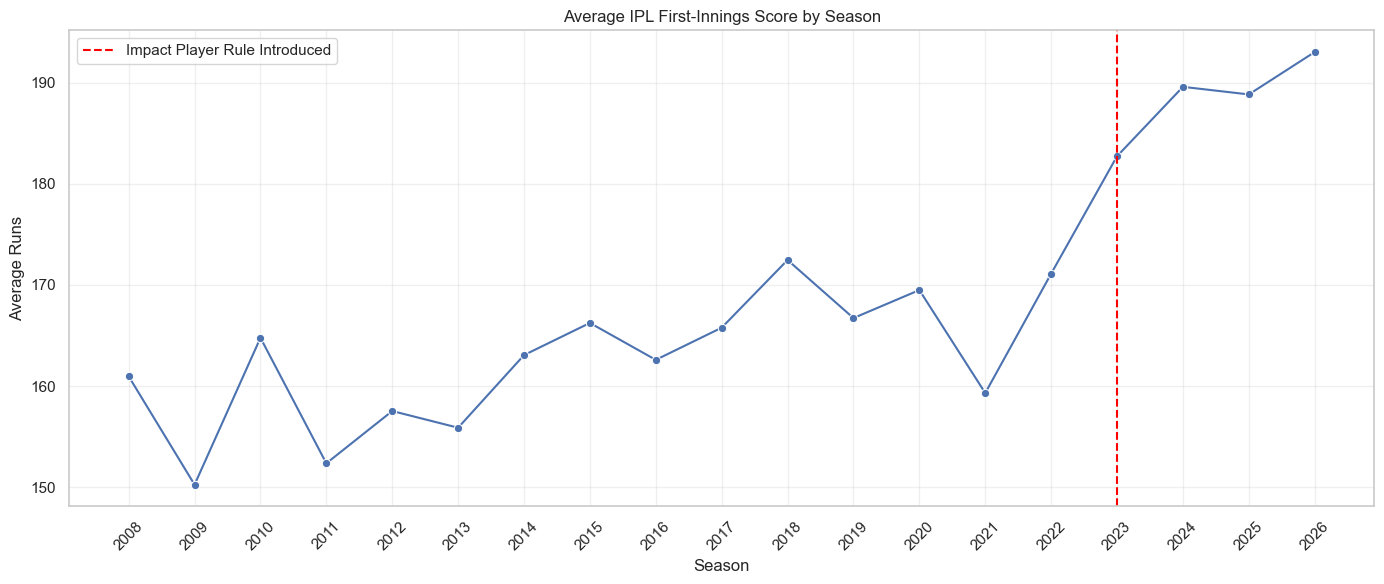

,era,average_score,total_matches
0,2023 onwards,188.54,293
1,Before 2023,162.41,950


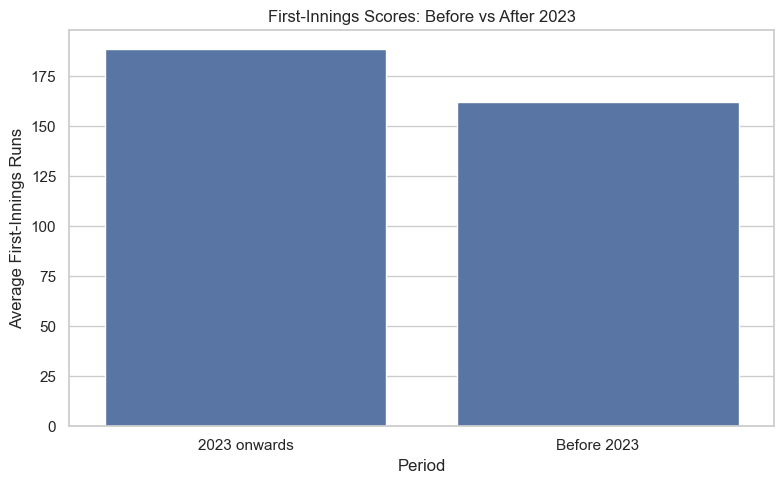

In [80]:
#Calculate average first-innings scores by season
season_scores = (
    matches_df.groupby('season')
    .agg(
        average_score=('first_innings_runs', 'mean'),
        median_score=('first_innings_runs', 'median'),
        total_matches=('match_id', 'nunique')
    )
    .reset_index()
)

season_scores['average_score'] = season_scores['average_score'].round(2)

display(season_scores)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=season_scores,
    x='season',
    y='average_score',
    marker='o'
)

plt.axvline(x=2023, color='red', linestyle='--',
            label='Impact Player Rule Introduced')

plt.title('Average IPL First-Innings Score by Season')
plt.xlabel('Season')
plt.ylabel('Average Runs')
plt.xticks(sorted(season_scores['season'].dropna().unique()),
           rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# season wise comparison
comparison_df = matches_df.dropna(
    subset=['season', 'first_innings_runs']
).copy()

comparison_df['era'] = comparison_df['season'].apply(
    lambda year: 'Before 2023' if year < 2023 else '2023 onwards'
)

# after 2023 changes only
era_scores = (
    comparison_df.groupby('era')
    .agg(
        average_score=('first_innings_runs', 'mean'),
        total_matches=('match_id', 'nunique')
    )
    .round(2)
    .reset_index()
)

display(era_scores)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=era_scores,
    x='era',
    y='average_score'
)

plt.title('First-Innings Scores: Before vs After 2023')
plt.xlabel('Period')
plt.ylabel('Average First-Innings Runs')
plt.tight_layout()
plt.show()

### Conclusion

The objective of this analysis is to determine whether average first-innings scores in the IPL have increased over time and whether scoring patterns changed after the Impact Player rule was introduced in 2023.

By analyzing average scores by season and comparing the periods before and after 2023, we can identify scoring trends, the highest- and lowest-scoring seasons, and differences between the two periods.

---
### Question :  IPL Batting Dominance — Who Are the Top Run-Scorers Across the Five Highest-Scoring Seasons, and How Do Their Batting Contributions Differ Across Powerplay, Middle Overs, and Death Overs?

Top 5 seasons: [2022, 2023, 2024, 2025, 2026]


,season,player,runs
370,2023,Shubman Gill,890
54,2022,JC Buttler,863
998,2026,V Suryavanshi,776
635,2025,B Sai Sudharsan,759
594,2024,V Kohli,741


Top 5 players across the selected seasons:


,player,runs
3,Shubman Gill,3181
4,V Kohli,3053
1,JC Buttler,2678
2,KL Rahul,2542
0,B Sai Sudharsan,2515


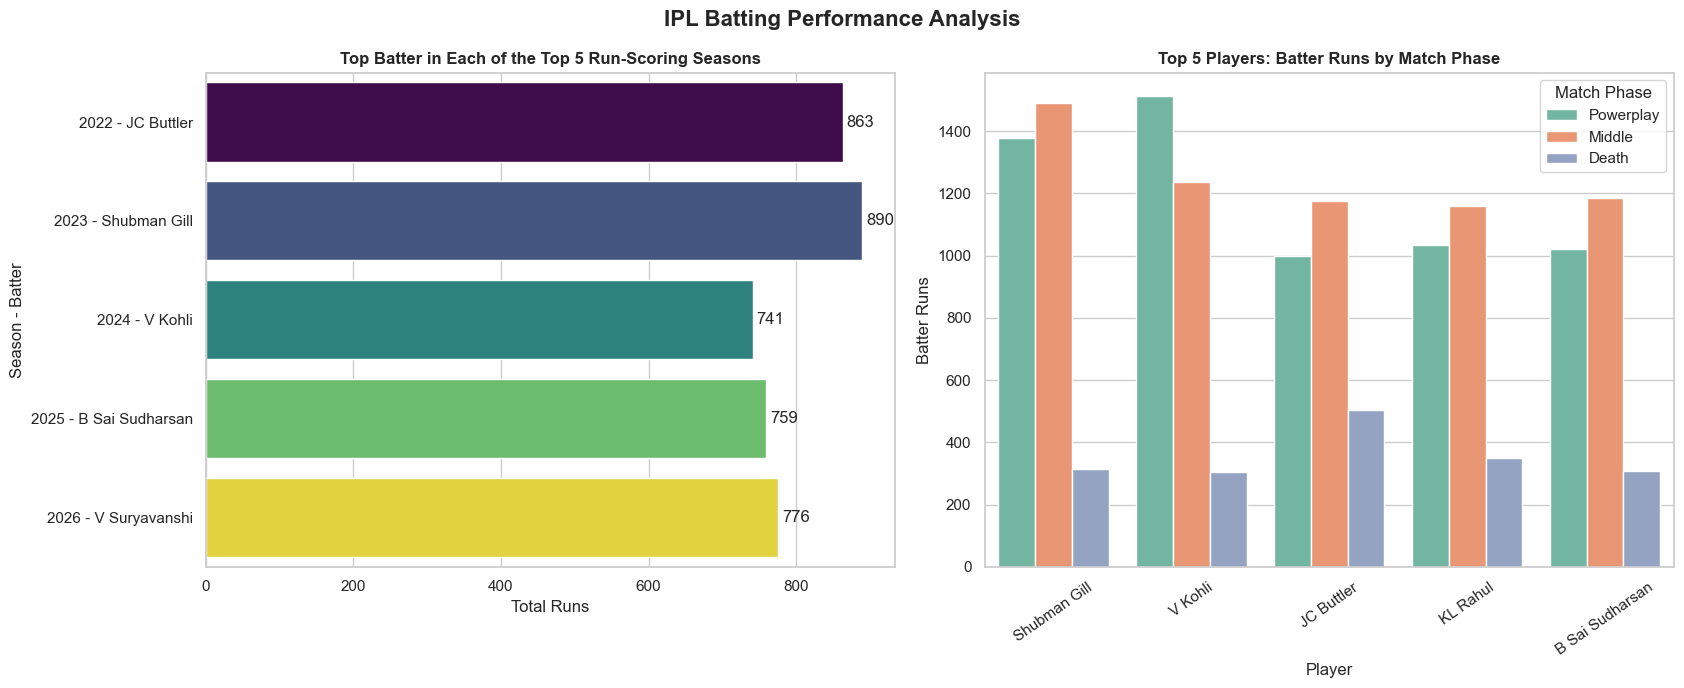

In [81]:

sns.set_theme(style="whitegrid")

# Find the top 5 seasons by batter runs

normal_balls = ball_df[ball_df['is_super_over'] == False].copy()  # not include the superover  

top_5_seasons = (
    normal_balls.groupby('season')['batter_runs']
    .sum()
    .nlargest(5)
    .index.tolist()
)

# Find the top batter in each selected season

season_player_runs = (
    player_season_df[
        player_season_df['season'].isin(top_5_seasons)
    ]
    .groupby(['season', 'player'], as_index=False)['runs']
    .sum()
)

top_batter_each_season = (
    season_player_runs
    .sort_values('runs', ascending=False)
    .groupby('season')
    .head(1)
    .sort_values('season')
)


# Find the top 5 players across those seasons

top_5_players = (
    season_player_runs.groupby('player')['runs']
    .sum()
    .nlargest(5)
    .index.tolist()
)

# Calculate each player's runs by phase
player_phase = (
    normal_balls[
        normal_balls['season'].isin(top_5_seasons)
        & normal_balls['batter'].isin(top_5_players)
        & normal_balls['phase'].isin(
            ['Powerplay', 'Middle', 'Death']
        )
    ]
    .groupby(['batter', 'phase'])['batter_runs']
    .sum()
    .reset_index()
    .rename(columns={'batter': 'player'})
)

# Keep players in descending total run order
player_order = (
    season_player_runs[
        season_player_runs['player'].isin(top_5_players)
    ]
    .groupby('player')['runs']
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

# Display results
print("Top 5 seasons:", sorted(top_5_seasons))

display(
    top_batter_each_season[
        ['season', 'player', 'runs']
    ].sort_values('runs', ascending=False)
)

print("Top 5 players across the selected seasons:")
display(
    season_player_runs[
        season_player_runs['player'].isin(top_5_players)
    ]
    .groupby('player', as_index=False)['runs']
    .sum()
    .sort_values('runs', ascending=False)
)

# Plot both charts in one window

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Top batter in each of the five seasons axis [0]

plot1 = top_batter_each_season.copy()
plot1['label'] = (
    plot1['season'].astype(str) + ' - ' + plot1['player']
)

sns.barplot(
    data=plot1,
    x='runs',
    y='label',
    hue='season',
    palette='viridis',
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    'Top Batter in Each of the Top 5 Run-Scoring Seasons',
    fontsize=12,
    fontweight='bold'
)
axes[0].set_xlabel('Total Runs')
axes[0].set_ylabel('Season - Batter')

# Add run labels, in percetage 

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3)

# Top 5 players' runs by phase axis[1]

sns.barplot(
    data=player_phase,
    x='player',
    y='batter_runs',
    hue='phase',
    hue_order=['Powerplay', 'Middle', 'Death'],
    order=player_order,
    palette='Set2',
    ax=axes[1]
)

axes[1].set_title(
    'Top 5 Players: Batter Runs by Match Phase',
    fontsize=12,
    fontweight='bold'
)
axes[1].set_xlabel('Player')
axes[1].set_ylabel('Batter Runs')
axes[1].tick_params(axis='x', rotation=35)
axes[1].legend(title='Match Phase')

plt.suptitle(
    'IPL Batting Performance Analysis',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()



### Conclusion

Identify the highest run-scoring batter in each of the five IPL seasons with the greatest combined batter runs, determine the top five players across those seasons, and compare their phase-wise batting contributions using batter runs, excluding extras, to understand how scoring patterns vary across different stages of a T20 innings.

---
### Question : Home Ground Advantage in the IPL — Which Five Teams Have Recorded the Most Wins at Their Home Venues, and How Do Their Home Win Percentages Compare Across IPL Seasons (2008–2026)?

,team,home_matches,home_wins,home_win_pct
1,Mumbai Indians,99,59,59.6
3,Kolkata Knight Riders,102,57,55.9
0,Chennai Super Kings,84,55,65.5
2,Royal Challengers Bengaluru,100,50,50.0
6,Sunrisers Hyderabad,70,43,61.4


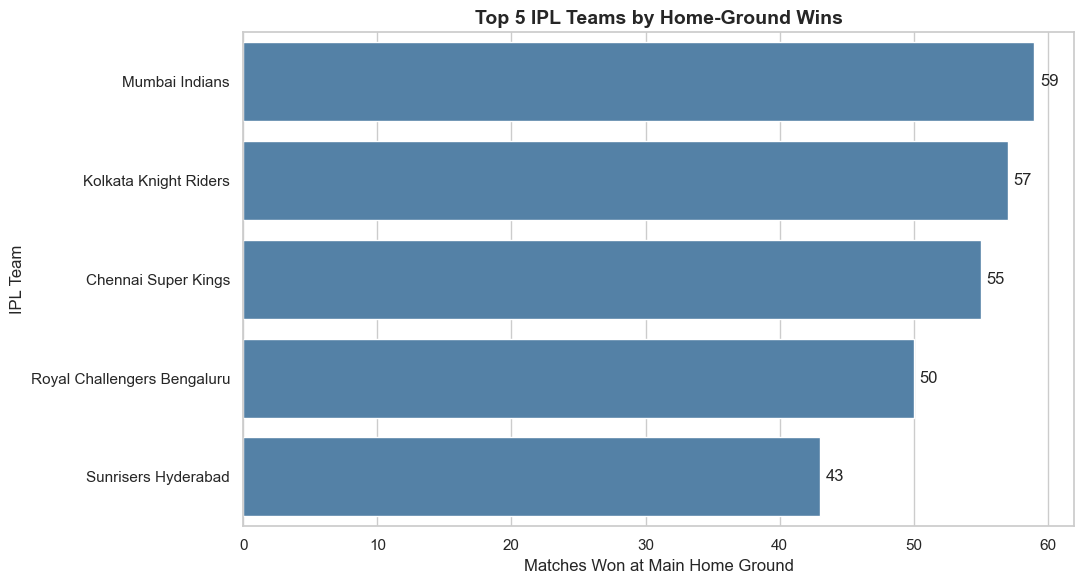

In [82]:

sns.set_theme(style="whitegrid")

# Map each team to its main home ground
home_venues = {
    'Chennai Super Kings': ['MA Chidambaram', 'M. A. Chidambaram'],
    'Mumbai Indians': ['Wankhede Stadium'],
    'Royal Challengers Bengaluru': ['M Chinnaswamy', 'M. Chinnaswamy'],
    'Kolkata Knight Riders': ['Eden Gardens'],
    'Rajasthan Royals': ['Sawai Mansingh'],
    'Delhi Capitals': ['Arun Jaitley', 'Feroz Shah Kotla'],
    'Sunrisers Hyderabad': ['Rajiv Gandhi International'],
    'Punjab Kings': ['IS Bindra', 'Maharaja Yadavindra Singh'],
    'Gujarat Titans': ['Narendra Modi Stadium'],
    'Lucknow Super Giants': ['BRSABV Ekana', 'Ekana Cricket']
}


# Find each teams home matches
df = matches_df.dropna(
    subset=['venue', 'winner', 'team1', 'team2']
).copy()

results = []

for team, venue_names in home_venues.items():
    venue_pattern = '|'.join(venue_names)

    home_matches = df[
        df['venue'].str.contains(
            venue_pattern, case=False, na=False, regex=True
        )
        & (
            (df['team1'] == team) |
            (df['team2'] == team)
        )
    ]

    # Count matches won at the home ground
    home_wins = (home_matches['winner'] == team).sum()
    total_home_matches = len(home_matches)

    if total_home_matches > 0:
        results.append({
            'team': team,
            'home_matches': total_home_matches,
            'home_wins': home_wins,
            'home_win_pct': round(
                home_wins / total_home_matches * 100, 1
            )
        })

home_stats = pd.DataFrame(results)

# Select the top 5 teams by home wins
top5_home = home_stats.nlargest(5, 'home_wins')

display(top5_home)

# Plot
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top5_home,
    x='home_wins',
    y='team',
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fmt='%.0f')

plt.title('Top 5 IPL Teams by Home-Ground Wins',
          fontsize=14, fontweight='bold')
plt.xlabel('Matches Won at Main Home Ground')
plt.ylabel('IPL Team')
plt.tight_layout()
plt.show()

### Conclusion

The home-ground analysis identifies the five IPL teams with the highest number of victories at their main home venues and compares their home win percentages. These results help reveal differences in teams' home-ground performance and whether playing at familiar venues is associated with a competitive advantage. However, home wins alone do not prove a home-ground advantage; the number of matches played, alternative venues, and overall team strength must also be considered.

---
### Question :How Strongly Are Individual Batting Performances, Including Total Runs Scored, Batting Average, Strike Rate, and Boundary-Hitting Ability, Associated with Player of the Match Awards, Match-Winning Contributions, and Overall Team Success, and Do Orange Cap Winners Consistently Translate Their Individual Scoring Achievements into Meaningful Victories, Playoff Qualifications, and IPL Championship Titles?

,player,total_runs,total_innings,avg_strike_rate,total_fifties,total_hundreds,potm_awards
756,V Kohli,9336,275,131.756316,68,9,22
570,RG Sharma,7329,275,133.421579,49,2,21
612,S Dhawan,6769,221,124.528235,51,2,12
174,DA Warner,6565,184,138.194667,62,4,18
338,KL Rahul,5815,149,135.093077,45,6,17
650,SK Raina,5528,200,135.895385,39,1,14
442,MS Dhoni,5439,241,141.061111,24,0,18
54,AM Rahane,5367,197,118.637778,35,2,13
685,SV Samson,5181,185,140.042857,27,5,14
33,AB de Villiers,5162,170,146.127143,40,3,25


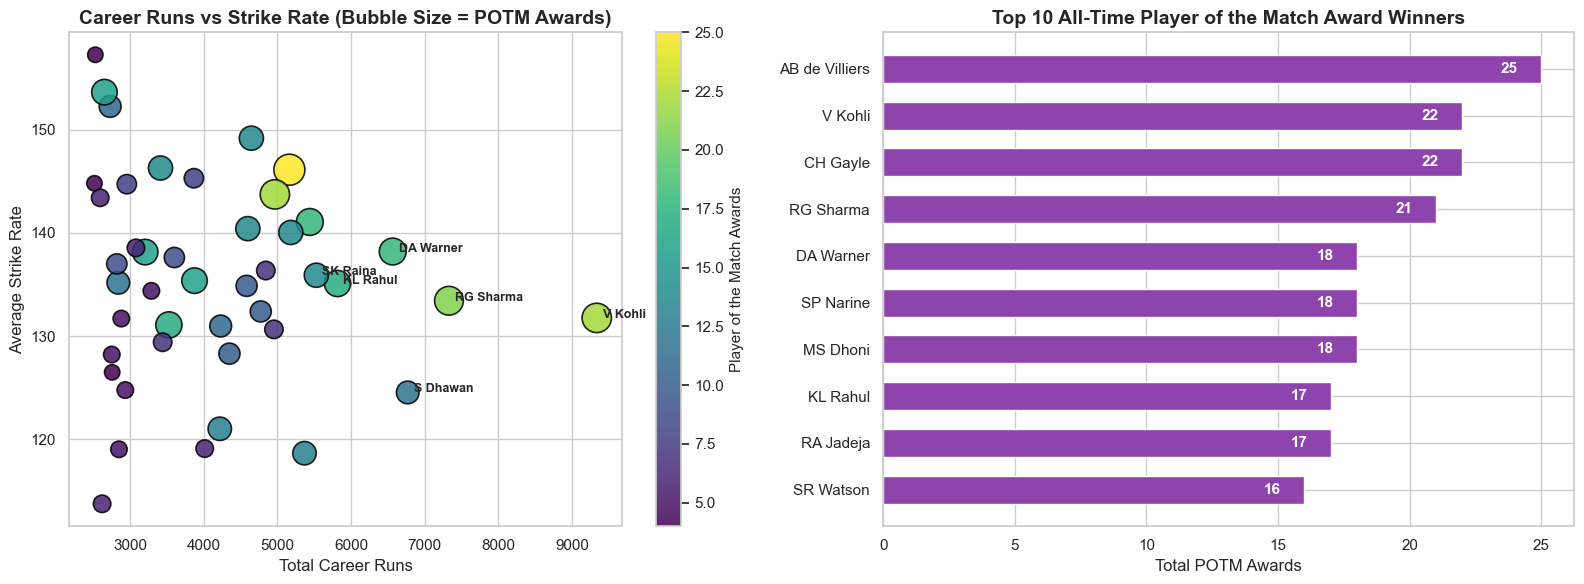

In [83]:
# Each player related total_runs, total_innings, avg_strike_rate, total_fifties, total_hundreds
player_career = (
    player_season_df.groupby('player')
    .agg(
        total_runs=('runs', 'sum'),
        total_innings=('innings_batted', 'sum'),
        avg_strike_rate=('strike_rate', 'mean'),
        total_fifties=('fifties', 'sum'),
        total_hundreds=('hundreds', 'sum')
    )
    .reset_index()
)

# find the player of match in each match
potm_counts = (
    matches_df[~matches_df['player_of_match'].isin(['Not Applicable', 'No Result'])]['player_of_match']
    .value_counts()
    .reset_index()
)

potm_counts.columns = ['player', 'potm_awards']

# Merge player career stats with match awards, not available award fill the zero
player_impact_df = pd.merge(player_career, potm_counts, on='player', how='left')
player_impact_df['potm_awards'] = player_impact_df['potm_awards'].fillna(0).astype(int)

# Filter  iconic players (2500+ runs)
top_players = player_impact_df[player_impact_df['total_runs'] >= 2500].sort_values(by='total_runs', ascending=False)
display(top_players.head(10))

# Visualizations using Scatter Plot & Top 10 POTM Winners Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#  Scatter Plot  Runs vs Strike Rate sized by POTM awards
scatter = axes[0].scatter(
    top_players['total_runs'], 
    top_players['avg_strike_rate'],
    s=top_players['potm_awards'] * 18 + 50,
    c=top_players['potm_awards'],
    cmap='viridis',
    alpha=0.85,
    edgecolors='black',
    linewidth=1.2
)
# this used represent side bar
cbar = fig.colorbar(scatter, ax=axes[0])  
cbar.set_label('Player of the Match Awards', fontsize=11)

# Annotate standout players, inside mention plot the 
for _, row in top_players.head(6).iterrows():
    axes[0].annotate(
        row['player'], 
        (row['total_runs'] + 80, row['avg_strike_rate']),
        fontsize=9, fontweight='bold'
    )

axes[0].set_title('Career Runs vs Strike Rate (Bubble Size = POTM Awards)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Career Runs')
axes[0].set_ylabel('Average Strike Rate')

# 2. Horizontal Bar Chart Top 10 POTM Award Winners axis[1]
top10_potm = potm_counts.head(10).sort_values(by='potm_awards', ascending=True)
axes[1].barh(top10_potm['player'], top10_potm['potm_awards'], color='#8e44ad', height=0.6)
axes[1].set_title('Top 10 All-Time Player of the Match Award Winners', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total POTM Awards')

for p in axes[1].patches:
    axes[1].annotate(
        f"{int(p.get_width())}", 
        (p.get_width() - 1.2, p.get_y() + p.get_height() / 2.),
        ha='center', va='center', color='white', fontweight='bold', fontsize=11
    )

plt.tight_layout()
plt.show()

#### Conclusion:
1. **Impact Over Pure Accumulation:** While anchors like Virat Kohli, Rohit Sharma, and Shikhar Dhawan lead total run tallies, explosive match-winners like AB de Villiers (25 POTMs) and Chris Gayle generate disproportionate match victories through devastating strike rates.
2. **The High Strike-Rate Premium:** Batters maintaining strike rates above 140+ with high volume win the most game-changing awards, showing that speed of scoring matters more than batting deep into overs.


---
### Question : Does Winning the Toss Give an Advantage, and How Do Teams Prefer to Play (Bat vs Field First)?

Objective : Examine whether winning the toss translates into match victory, how team toss decisions have evolved across IPL history, and whether chasing (fielding first) statistically yields higher success rates.

,toss_decision,total_matches,win_rate,win_rate_pct
0,bat,414,0.454106,45.41
1,field,820,0.543902,54.39


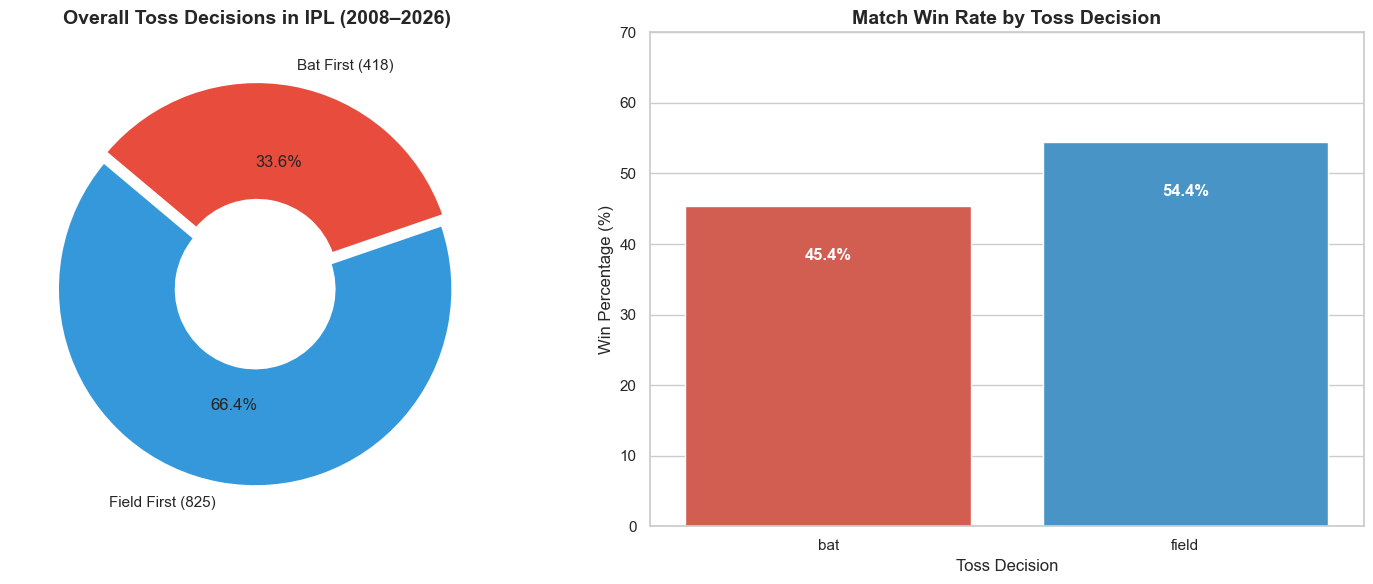

In [84]:
# Distribution of Toss Decisions
toss_counts = matches_df['toss_decision'].value_counts()

#  Win rate by Toss Decision
valid_matches = matches_df[matches_df['winner'] != 'No Result'].copy()
valid_matches['toss_won_match'] = (valid_matches['toss_winner'] == valid_matches['winner'])

win_by_decision = (
    valid_matches.groupby('toss_decision')['toss_won_match']
    .agg(total_matches='count', win_rate='mean')
    .reset_index()
)
win_by_decision['win_rate_pct'] = (win_by_decision['win_rate'] * 100).round(2)


# Display summary table
display(win_by_decision)

# Visualizations using Donut Chart and Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Donut Chart Toss Decisions , and display to the axis[0] mean first part
colors = ['#3498db', '#e74c3c']
axes[0].pie(
    toss_counts,
    labels=[f"Field First ({toss_counts['field']})", f"Bat First ({toss_counts['bat']})"],
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    explode=(0.05, 0),
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2)
)
axes[0].set_title('Overall Toss Decisions in IPL (2008–2026)', fontsize=14, fontweight='bold')

# Bar Chart Win Rate by Toss Decision and display the axis[1] and mean column two (right side )
sns.barplot(
    data=win_by_decision,
    x='toss_decision',
    y='win_rate_pct',
    hue='toss_decision',
    palette=['#e74c3c', '#3498db'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Match Win Rate by Toss Decision', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Win Percentage (%)')
axes[1].set_xlabel('Toss Decision')
axes[1].set_ylim(0, 70)

#this is the add the percentage into plots
for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height() - 7),
        ha='center', va='center', color='white', fontweight='bold', fontsize=12
    )

plt.tight_layout()
plt.show()

#### Conclusion:
1. **Fielding First Preference:** Captains heavily prefer to field first (66.4% of all toss wins), opting to chase rather than set a target.
2. **Clear Advantage in Chasing:** Teams electing to field first win **54.4%** of matches, compared to only **45.4%** when choosing to bat first. Winning the toss and bowling first provides a measurable ~9% advantage.

---
### Question : Breakdown the match pahes powerplay (overs 1-6), Middle overs (over 7-15) Death overs (overs 16-20), In Which Phase (Powerplay, Middle, Death) Are Matches Won, and Where Do Boundaries Dominate?


,phase,total_runs,boundary_run_pct,run_rate,balls_per_wicket
0,Powerplay,120188,66.75,8.09,24.9
1,Middle,174283,50.47,7.95,23.0
2,Death,106952,59.8,10.06,11.8


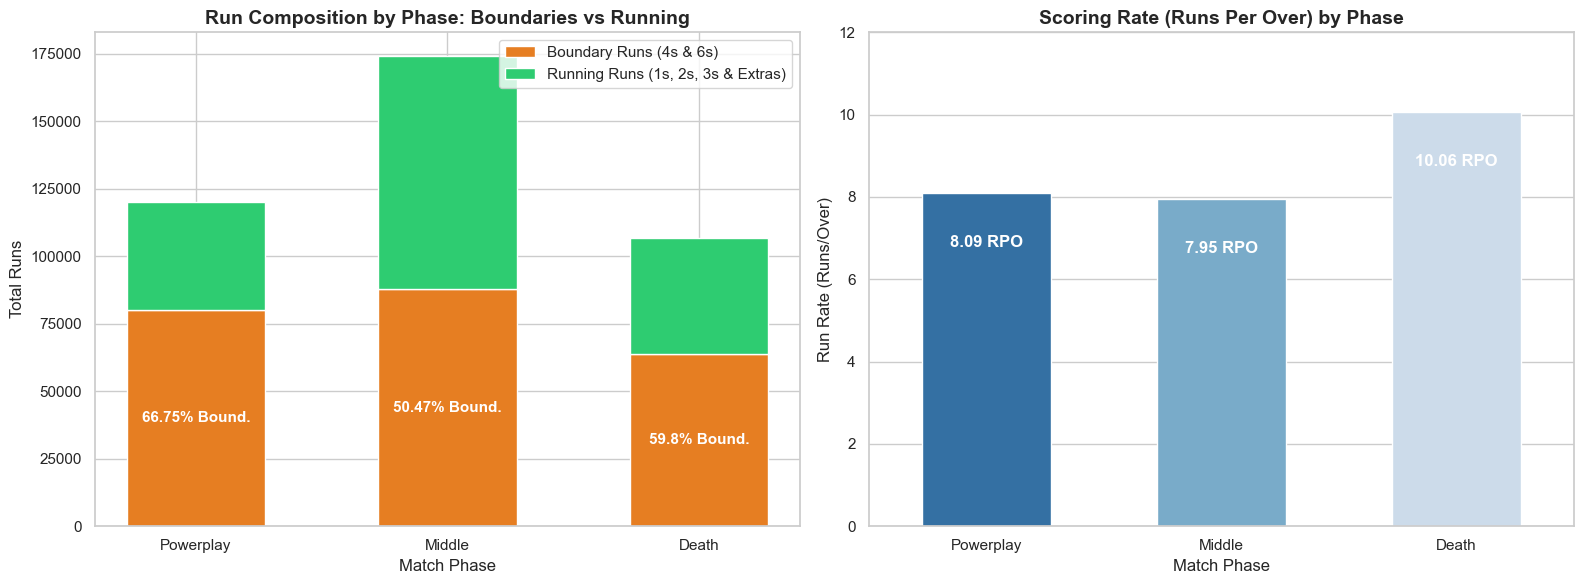

In [85]:
# Aggregate ball-by-ball performance by phase, In each phase related  find the total_balls, total_runs, fours, sixes, wickets
phase_order = ['Powerplay', 'Middle', 'Death']
phase_df = ball_df[ball_df['phase'].isin(phase_order)].copy()

phase_stats = (
    phase_df.groupby('phase')
    .agg(
        total_balls=('is_legal_ball', 'sum'),
        total_runs=('total_runs', 'sum'),
        fours=('is_four', 'sum'),
        sixes=('is_six', 'sum'),
        wickets=('is_wicket', 'sum')
    )
    .loc[phase_order]
    .reset_index()
)


phase_stats['boundary_runs'] = phase_stats['fours'] * 4 + phase_stats['sixes'] * 6
phase_stats['running_runs'] = phase_stats['total_runs'] - phase_stats['boundary_runs']
phase_stats['boundary_run_pct'] = ((phase_stats['boundary_runs'] / phase_stats['total_runs']) * 100).round(2) #calculate percentage
phase_stats['run_rate'] = (phase_stats['total_runs'] / (phase_stats['total_balls'] / 6)).round(2)
phase_stats['balls_per_wicket'] = (phase_stats['total_balls'] / phase_stats['wickets']).round(1)


display(phase_stats[['phase', 'total_runs', 'boundary_run_pct', 'run_rate', 'balls_per_wicket']])

# Visualizations using Stacked Bar Chart & Scoring Rate Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Stacked Bar Chart - Boundary vs Running Runs
axes[0].bar(phase_stats['phase'], phase_stats['boundary_runs'], label='Boundary Runs (4s & 6s)', color='#e67e22', width=0.55)
axes[0].bar(phase_stats['phase'], phase_stats['running_runs'], bottom=phase_stats['boundary_runs'], label='Running Runs (1s, 2s, 3s & Extras)', color='#2ecc71', width=0.55)
axes[0].set_title('Run Composition by Phase: Boundaries vs Running', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Runs')
axes[0].set_xlabel('Match Phase')
axes[0].legend(loc='upper right')

#put percentage in the inside of the bar plot
for i, row in phase_stats.iterrows():
    axes[0].annotate(f"{row['boundary_run_pct']}% Bound.", 
                     (i, row['boundary_runs'] / 2), 
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# 2. Bar Chart  Run Rate per Phase - axis 1
sns.barplot(
    data=phase_stats, 
    x='phase', 
    y='run_rate', 
    hue='phase', 
    palette='Blues_r', 
    legend=False, 
    ax=axes[1],
    width=0.55
)
axes[1].set_title('Scoring Rate (Runs Per Over) by Phase', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Run Rate (Runs/Over)')
axes[1].set_xlabel('Match Phase')
axes[1].set_ylim(0, 12)

# percentage put to the inside of the bar plote
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f} RPO", 
                     (p.get_x() + p.get_width() / 2., p.get_height() - 1.2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

#### Conclusion :
1. **Powerplay Boundary Surge:** The Powerplay sees the highest proportion of boundary scoring (**66.7%** of runs come from 4s and 6s), with batters capitalizing on field restrictions while maintaining safety (24.9 balls per wicket).
2. **Death Overs Mayhem:** Run rates peak at **10.4 RPO** during the Death overs, but wickets fall at more than double the frequency (**11.8 balls per dismissal**).
3. **Middle Overs Consolidation:** Middle overs feature the lowest boundary proportion (50.5%) and focus on strike rotation and anchor building.


---
### Question : How Have Bowlers’ Average Economy Rates, Dot-Ball Percentages, Wicket-Taking Performance, and Run-Conceding Patterns Evolved Over Time, and To What Extent Have These Changes Reflected Bowlers’ Ability to Control Scoring Rates Amid Increasing Batting Aggression and the Evolution of T20 Cricket?

,season,avg_economy,dot_ball_pct,total_wickets
11,2019,8.225435,36.56,539
12,2020,8.093404,36.15,545
13,2021,7.726977,37.54,537
14,2022,8.279474,38.07,708
15,2023,8.782881,34.19,705
16,2024,9.322807,33.50,703
17,2025,9.272222,33.35,680
18,2026,9.737377,33.42,727


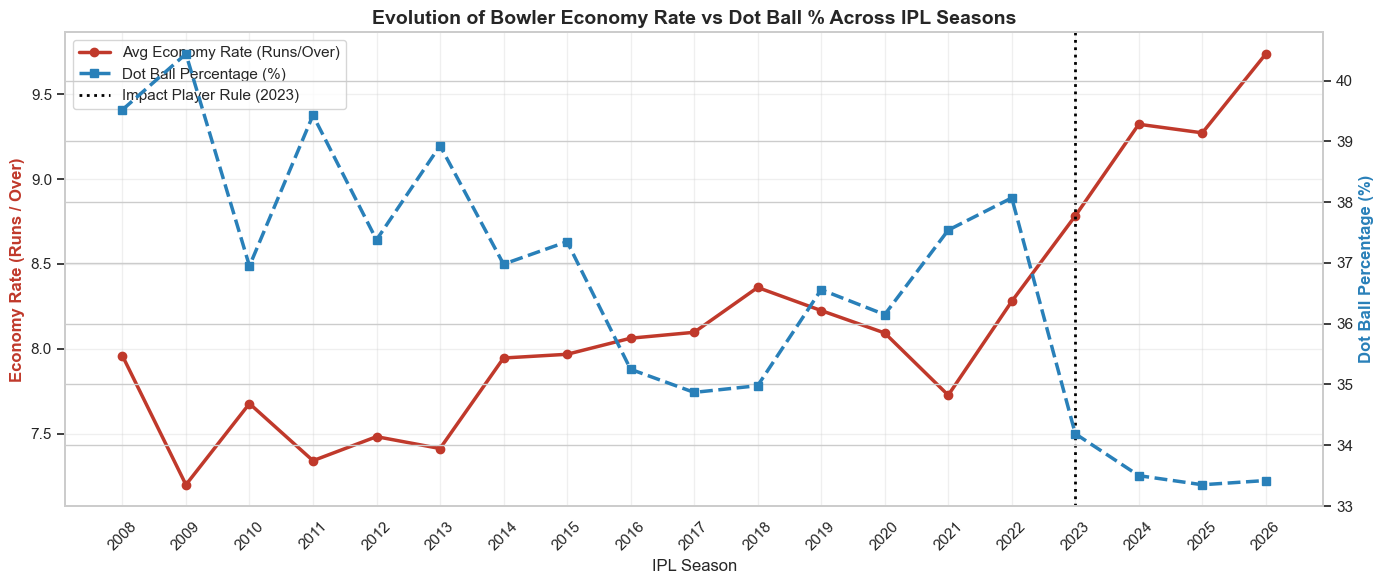

In [86]:
# Calculate season-wise bowling economy and dot ball percetage from player_season_df
bowling_season = (
    player_season_df[player_season_df['overs_bowled'] >= 20]
    .groupby('season')
    .agg(
        avg_economy=('economy', 'mean'),
        total_overs=('overs_bowled', 'sum'),
        total_dot_balls=('dot_balls', 'sum'),
        total_wickets=('wickets', 'sum')
    )
    .reset_index()
)

#dot ball percentage
bowling_season['dot_ball_pct'] = (
    (bowling_season['total_dot_balls'] / (bowling_season['total_overs'] * 6)) * 100
).round(2)

display(bowling_season[['season', 'avg_economy', 'dot_ball_pct', 'total_wickets']].tail(8))

# Visualization Dual-Axis Line Chart
fig, ax1 = plt.subplots(figsize=(14, 6))

ax2 = ax1.twinx()

line1 = ax1.plot(
    bowling_season['season'], 
    bowling_season['avg_economy'], 
    color='#c0392b', 
    marker='o', 
    linewidth=2.5, 
    label='Avg Economy Rate (Runs/Over)'
)

line2 = ax2.plot(
    bowling_season['season'], 
    bowling_season['dot_ball_pct'], 
    color='#2980b9', 
    marker='s', 
    linewidth=2.5, 
    linestyle='--', 
    label='Dot Ball Percentage (%)'
)

# Reference line for Impact Player Rule
vline = ax1.axvline(x=2023, color='black', linestyle=':', linewidth=2, label='Impact Player Rule (2023)')

ax1.set_xlabel('IPL Season', fontsize=12)
ax1.set_ylabel('Economy Rate (Runs / Over)', color='#c0392b', fontsize=12, fontweight='bold')
ax2.set_ylabel('Dot Ball Percentage (%)', color='#2980b9', fontsize=12, fontweight='bold')
plt.title('Evolution of Bowler Economy Rate vs Dot Ball % Across IPL Seasons', fontsize=14, fontweight='bold')

# Combine legends from both axes
lines = line1 + line2 + [vline]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

ax1.set_xticks(sorted(bowling_season['season'].unique()))
ax1.tick_params(axis='x', rotation=45)
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Conclusion & Key Insights:
1. **Dramatic Surge in Economy Rates:** Bowler economy rates remained stable between 7.5 and 7.8 from 2008 to 2020, but experienced a sharp escalation starting in 2022 (8.28), climbing to **8.78 in 2023**, **9.32 in 2024**, and reaching **9.74 in 2026**.
2. **Decline in Dot Ball %:** The percentage of dot balls steadily decreased from ~38–40% in earlier eras to ~33.4% in recent tournaments.


---
### Question : How Do Different Stadiums Influence First-Innings Scores, Batting and Bowling Performance, and the Likelihood of Winning When Batting First Compared with Chasing a Target?

,venue,total_matches,avg_first_innings,chase_win_pct
20,Narendra Modi Stadium (Motera),53,180.7,49.1
4,Brabourne Stadium,27,178.5,48.1
1,BRSABV Ekana Cricket Stadium,28,176.6,57.1
16,M Chinnaswamy Stadium,101,174.8,55.4
36,Wankhede Stadium,132,173.1,54.5
0,Arun Jaitley Stadium,103,172.9,51.5
10,Eden Gardens,105,169.7,55.2
28,Sawai Mansingh Stadium,68,169.1,64.7
26,"Rajiv Gandhi International Stadium, Uppal",89,168.7,52.8
25,"Punjab Cricket Association IS Bindra Stadium, ...",61,168.3,55.7


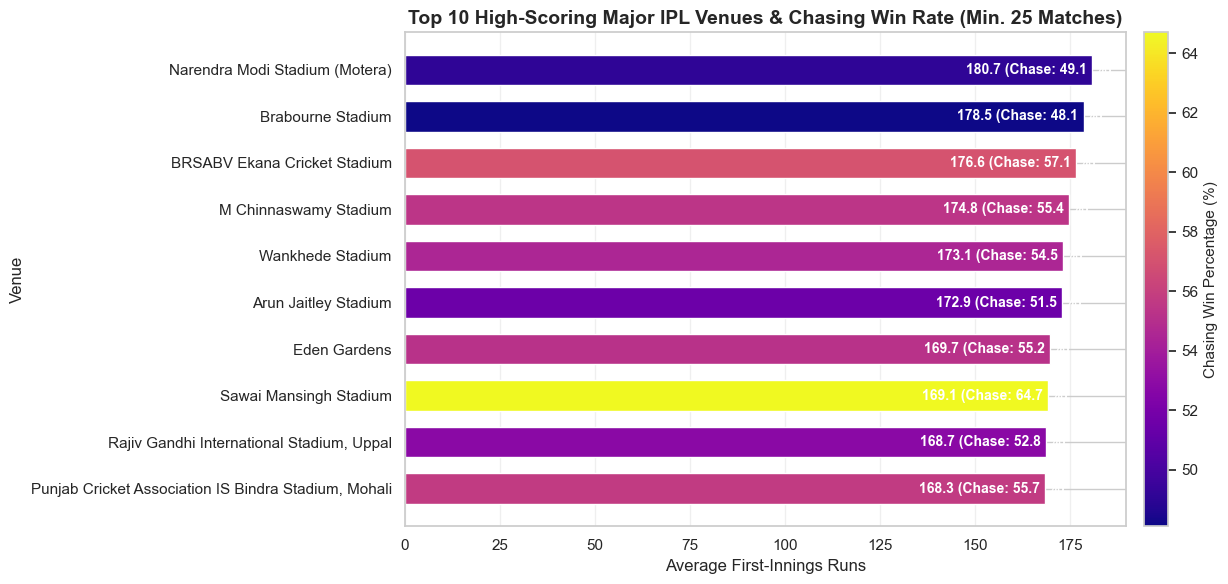

In [87]:
# Filter matches with a decisive result and aggregate venue statistics
venue_analysis = (
    matches_df[~matches_df['winner'].isin(['No Result'])]
    .groupby('venue')
    .agg(
        total_matches=('match_id', 'count'),
        chasing_wins=('win_by_wickets', lambda x: (x > 0).sum()),  #second innigns winning
        avg_first_innings=('first_innings_runs', 'mean')
    )
    .reset_index()
)


# Consider venues with at least 25 matches for statistical reliability
major_venues = venue_analysis[venue_analysis['total_matches'] >= 25].copy()
major_venues['chase_win_pct'] = ((major_venues['chasing_wins'] / major_venues['total_matches']) * 100).round(1)
major_venues['avg_first_innings'] = major_venues['avg_first_innings'].round(1)
major_venues = major_venues.sort_values(by='avg_first_innings', ascending=False).head(10) # sort the avg_first_innings 

display(major_venues[['venue', 'total_matches', 'avg_first_innings', 'chase_win_pct']])

# Visualization Horizontal Ranked Bar Chart
plt.figure(figsize=(13, 6))

# This is the normalize min and max 
norm = plt.Normalize(major_venues['chase_win_pct'].min(), major_venues['chase_win_pct'].max())
colors = plt.cm.plasma(norm(major_venues['chase_win_pct']))

bars = plt.barh(major_venues['venue'], major_venues['avg_first_innings'], color=colors, height=0.65)
plt.title('Top 10 High-Scoring Major IPL Venues & Chasing Win Rate (Min. 25 Matches)', fontsize=14, fontweight='bold')
plt.xlabel('Average First-Innings Runs', fontsize=12)
plt.ylabel('Venue', fontsize=12)
plt.gca().invert_yaxis()

# Add colorbar for chasing win %
sm = plt.cm.ScalarMappable(cmap='plasma', norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label('Chasing Win Percentage (%)', fontsize=11)

for bar, (_, row) in zip(bars, major_venues.iterrows()):
    plt.text(
        bar.get_width() - 14, 
        bar.get_y() + bar.get_height() / 2, 
        f"{row['avg_first_innings']:.1f} (Chase: {row['chase_win_pct']}  %)",
        ha='center', va='center', color='white', fontweight='bold', fontsize=10
    )

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

#### Conclusion & Key Insights:
1. **High-Scoring Havens:** Venues like Narendra Modi Stadium (Motera), M. Chinnaswamy Stadium, Wankhede Stadium, and Eden Gardens consistently average over 165+ runs in the first innings.
2. **Chasing Strongholds:** Sawai Mansingh Stadium (64.7% chase win rate), BRSABV Ekana Stadium (57.1%), and M. Chinnaswamy Stadium (55.4%) heavily reward teams fielding first.


## Step 7: Project Conclusion 

---

### 1. Executive Summary
This Exploratory Data Analysis (EDA) conducted an in-depth investigation across **19 editions of the Indian Premier League (2008–2026)**, analyzing **1,243 fixtures**, **295,732 deliveries**, and **3,339 player-season records**. Through rigorous statistical synthesis and visualization across match-level, delivery-level, and player-level dimensions, this project maps the structural metamorphosis of T20 cricket from an exploratory tournament into a hyper-aggressive, data-driven, boundary-centric sport.

---

### 2. Core Points

#### A. The Scoring Inflation & Impact Player Revolution (2023–2026)
* **The +26 Run Benchmark Shift:** First-innings scoring remained remarkably stable between 2008 and 2022, averaging **162.41 runs**. Following the formal introduction of the Impact Player rule in 2023, average first-innings scores exploded to **188.54 runs** across 293 fixtures — an unprecedented surge of **+26.13 runs per innings**.
* **Normalization of 200+ Totals:** What once represented an outlier or match-winning total before 2022 has become the baseline par score on flat batting decks.

#### B. The Plight of the Modern Bowler & Diminishing Dot-Ball Pressure
* **Economy Escalation:** Bowling economy rates maintained equilibrium around **7.50 – 8.10 RPO** for over a decade (7.73 as recently as 2021). Post-2022, bowling economies spiked precipitously to **8.78 (2023)**, **9.32 (2024)**, and crested at **9.74 RPO in 2026**.
* **Erosion of Dot-Ball Percentage:** Dot-ball percentages dropped from historical norms of **~38%–40%** to **33.3%–33.5%**. Batters now consistently convert defensive deliveries into singles or boundary attempts, significantly weakening traditional bowling pressure tactics.

#### C. Toss Strategy & Chasing Supremacy
* **Captains' Unanimous Consensus:** Captains overwhelmingly elect to field first upon winning the toss (**66.4%** of all fixtures, 820 matches).
* **The Statistical Chasing Edge:** Teams electing to field first achieve a **54.39% win rate**, compared to **45.41%** for teams electing to bat first. This **~9.0% tactical dividend** validates the strategic preference for chasing, driven by dew factors, target clarity, and deeper batting lineups.

#### D. Phase-Wise Anatomy of a T20 Innings
* **Powerplay (Overs 1–6) — Boundary Exploitation:** Yields the highest boundary dependency (**66.75% of runs come from 4s and 6s**) at **8.09 RPO**, with minimal risk (**24.9 balls per dismissal**).
* **Middle Overs (Overs 7–15) — Tactical Consolidation:** Run rate dips slightly to **7.95 RPO** with the lowest boundary proportion (**50.47%**), emphasizing strike rotation and wicket preservation.
* **Death Overs (Overs 16–20) — High-Stakes Volatility:** Run rates skyrocket to **10.06 RPO** with **59.80% boundary runs**, but dismissals occur at more than double the frequency (**11.8 balls per wicket**).

#### E. Impact Over Accumulation: The Batting Metric Paradigm Shift
* **Strike Rate Dominance:** While classic accumulators (Virat Kohli with 9,336 career runs, Rohit Sharma with 7,329 runs, Shikhar Dhawan with 6,769 runs) lead the aggregate charts, high-impact batters generate disproportionately more match-winning outcomes.
* **The AB de Villiers Benchmark:** AB de Villiers accrued **25 Player of the Match awards** across just 170 innings with an elite strike rate of **146.13**, proving that strike rate and boundary frequency heavily outperform raw run accumulation in dictating fixture outcomes.
* **Modern Batting Vanguard (2022–2026):** Shubman Gill (3,181 runs), Virat Kohli (3,053 runs), Jos Buttler (2,678 runs), KL Rahul (2,542 runs), and B. Sai Sudharsan (2,515 runs) exemplify the modern archetype of blending volume with sustained high tempo.

#### F. Fortress Effect & Venue Archetypes
* **Home Ground Mastery:** Chennai Super Kings hold the gold standard of home-ground dominance at MA Chidambaram Stadium (**65.48% win rate** across 84 matches), followed by Sunrisers Hyderabad (**61.43%**) and Mumbai Indians (**59.60%** at Wankhede). Conversely, RCB at M. Chinnaswamy Stadium (**50.00%**) illustrates how high-scoring, flat venues neutralize home-pitch advantages.
* **Ground Dynamics:** Venues such as Narendra Modi Stadium (180.7 avg 1st innings), Brabourne (178.5), and Ekana (176.6) lead overall scoring, while Sawai Mansingh Stadium presents the steepest chasing bias (**64.7% chase win rate**).

---

### 3. Actionable Strategic Recommendations for Franchises

| Tactical Pillar | Key Strategic Recommendation |
| :--- | :--- |
| **Auction Strategy** | Prioritize batters with career strike rates > 140+ over pure anchors; allocate premium purse toward death-overs execution bowlers who can sustain sub-9.5 economy rates. |
| **Toss Directives** | Elect to **field first** in >85% of standard conditions, especially at high-scoring venues (Sawai Mansingh, Chinnaswamy, Eden Gardens) where chasing win rates exceed 55%. |
| **Powerplay Strategy** | Maximize field restrictions by deploying designated aggressors instructed to target the 66%+ boundary threshold without hesitation. |
| **Impact Player Usage** | Utilize the 8th batter cushion to allow top-order batters to operate with complete freedom rather than self-preserving their wickets. |
| **Bowling Tactics** | Pivot away from trying to bowl defensive dot balls; focus on wicket-taking deliveries in the middle overs as breaking partnerships is the only reliable brake on escalating run rates. |

---

### 4. Concluding Remarks
The IPL has evolved into an offensive sporting spectacle where traditional boundary markers and conservative anchor strategies have been superseded by mathematical aggression, analytical matchup optimization, and batting depth. As the tournament continues to push modern athletic and tactical limits, teams that align squad construction, toss tactics, and phase execution with these empirical insights will consistently command the competitive advantage.

